# MoE load-balancing lab

Why do Mixture-of-Experts routers pile tokens onto a few experts, and which fixes produce a model that actually uses
all of its experts? All CPU-scale results are already in `results/` (see `README.md`). This notebook is for the parts
that need a GPU or Hugging Face access, and for re-running anything.

| experiment | what | where it runs |
|---|---|---|
| E1 / E2 | mechanisms and fixes (synthetic) | CPU, results in repo |
| E4 / E5 / E6 | per-method tuning, pre-registered held-out test, depth & representation pathway | CPU, results in repo |
| E3 v2 `--preset cpu` | 4-layer byte-level MoE LM | CPU, results in repo |
| **E3 v2 `--preset gpu`** | 6-layer, 32-expert LM, 10k steps | **GPU (this notebook)**; 19 of 21 runs in repo (Kaggle T4) |
| **E7** | routing over a real MoE's pretraining checkpoints (OLMoE) | **GPU + Hugging Face (this notebook)** |

## Environment check (Kaggle / Colab)

Run this first. On Kaggle it needs **Settings → Internet: On** (phone-verified account) and, for the GPU sections,
**Accelerator: GPU T4 ×2** (a P100 may not work with the preinstalled PyTorch). `torch`, `numpy`, `matplotlib`,
`pytest`, `transformers`, `accelerate` and `huggingface_hub` are preinstalled there, so the `pip install` below only
confirms them.

This cell checks the internet and the GPU, sends the Hugging Face cache to scratch space (`/kaggle/temp`), and sets
`E7_DTYPE` / `E7_MAX_CKPTS` for the E7 cell. T4/P100 GPUs have no native bf16, so E7 falls back to float16 there, and
the number of checkpoints is capped by free disk (each OLMoE revision is ~14 GB and the script never deletes them).
Kaggle sessions last at most 12 h and only `/kaggle/working` is kept as output; the clone cell below puts the repo
(and so `results/`) there. Use **Save Version → Save & Run All**: its output is kept even if it hits the time limit.
With T4 ×2 the scripts use both GPUs (one E3 run per GPU; E7 splits the model across both).

In [1]:
import os, shutil, socket

ON_KAGGLE = os.path.exists("/kaggle/working")
if ON_KAGGLE:
    os.makedirs("/kaggle/temp/hf", exist_ok=True)
    os.environ["HF_HOME"] = "/kaggle/temp/hf"  # big checkpoint downloads go to scratch, not the saved output

def reachable(host):
    try:
        socket.create_connection((host, 443), timeout=5).close()
        return True
    except OSError:
        return False

for host, why in [("github.com", "git clone"), ("raw.githubusercontent.com", "Shakespeare corpus (E3)"),
                  ("huggingface.co", "OLMoE checkpoints (E7)")]:
    print(f"{'ok     ' if reachable(host) else 'BLOCKED'} {host:28s} {why}")
if ON_KAGGLE:
    print("If any host is BLOCKED: Settings -> Internet -> On, then restart the session.")

import torch
E7_DTYPE, E7_MAX_CKPTS = "bfloat16", 10
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
if N_GPUS:
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name}, {props.total_memory / 2**30:.1f} GiB, sm_{props.major}{props.minor}, {N_GPUS} device(s)")
    try:
        (torch.zeros(1, device="cuda") + 1).item()
    except Exception as e:  # e.g. P100 (sm_60) with a PyTorch build that dropped it
        print("CUDA is visible but a kernel failed -> switch the accelerator to T4:", e)
    if props.major < 8:
        E7_DTYPE = "float16"
    if props.total_memory * N_GPUS < 24 * 2**30:
        print("WARNING: OLMoE-1B-7B is 13.8 GB in 16-bit; with < 24 GB of GPU memory in total E7 may run out of memory.")
else:
    print("No GPU: the GPU cells will skip themselves; only the CPU sections (quick look, re-runs, analysis) run.")
    print("On Kaggle: Settings -> Accelerator -> GPU T4 x2, then restart the session.")

hf_home = os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface"))
os.makedirs(hf_home, exist_ok=True)
free_gb = shutil.disk_usage(hf_home).free / 2**30
# one download per chosen revision plus `main`, ~15 GB each
E7_MAX_CKPTS = max(0, min(E7_MAX_CKPTS, int(free_gb // 15) - 1))
print(f"free disk for HF cache: {free_gb:.0f} GiB -> E7_MAX_CKPTS={E7_MAX_CKPTS}, E7_DTYPE={E7_DTYPE}")
if E7_MAX_CKPTS < 2:
    print("WARNING: not enough disk for a useful E7 run; skip E7 or free space / use a smaller MoE repo.")

ok      github.com                   git clone
ok      raw.githubusercontent.com    Shakespeare corpus (E3)
ok      huggingface.co               OLMoE checkpoints (E7)
If any host is BLOCKED: Settings -> Internet -> On, then restart the session.
GPU: Tesla T4, 14.6 GiB, sm_75, 2 device(s)
free disk for HF cache: 1070 GiB -> E7_MAX_CKPTS=10, E7_DTYPE=float16


In [2]:
# Clone the repo. For a private repo, use a token: https://<TOKEN>@github.com/westhauxstripclub/colab.git
BRANCH = "claude/vigilant-curie-gn5azm"
!git clone -b {BRANCH} https://github.com/westhauxstripclub/colab.git moe-lab
%cd moe-lab
!pip -q install -r requirements.txt
!python -m pytest -q tests

Cloning into 'moe-lab'...
remote: Enumerating objects: 241, done.
remote: Counting objects: 100% (241/241), done.
remote: Compressing objects: 100% (173/173), done.
remote: Total 241 (delta 109), reused 157 (delta 59), pack-reused 0 (from 0)
Receiving objects: 100% (241/241), 8.40 MiB | 15.68 MiB/s, done.
Resolving deltas: 100% (109/109), done.
/kaggle/working/moe-lab
......................                                                   [100%]
22 passed in 9.42s


In [3]:
# Resume: copy finished runs from earlier versions' output. On Kaggle, "Add Input" -> Your Work -> this notebook's
# previous version; its /kaggle/working shows up under /kaggle/input/. Runs already in results/ are skipped by every
# script, so only unfinished ones run again.
import glob, os, shutil
copied = 0
for src in glob.glob("/kaggle/input/**/moe-lab/results/*/*.json", recursive=True):
    exp = os.path.basename(os.path.dirname(src))
    dst = os.path.join("results", exp, os.path.basename(src))
    if not os.path.exists(dst):
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy(src, dst)
        copied += 1
print(f"copied {copied} finished run(s) from /kaggle/input")
for exp in ("e3v2_lm_gpu", "e7_real_checkpoints"):
    print(f"results/{exp}: {len(glob.glob(f'results/{exp}/*.json'))} finished")

copied 0 finished run(s) from /kaggle/input
results/e3v2_lm_gpu: 19 finished
results/e7_real_checkpoints: 0 finished


## Quick look: one run without balancing vs. one with a strong aux loss

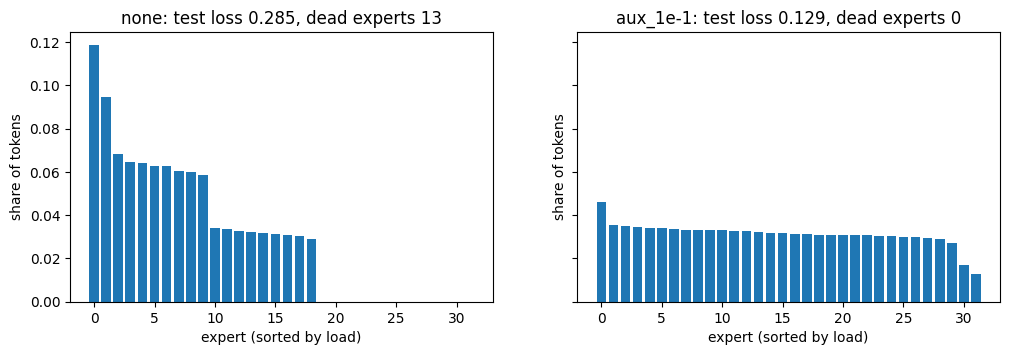

In [4]:
import sys; sys.path.insert(0, '.')
import matplotlib.pyplot as plt
from moe_lab.train_synthetic import SynthRunConfig, run_synthetic

base = dict(moe=dict(d_hidden=8, n_experts=32), task=dict(n_clusters=32, n_train=32000, n_val=8000), seed=0)
runs = {name: run_synthetic(SynthRunConfig(name=name, **{**base, 'moe': {**base['moe'], **extra}}))
        for name, extra in [('none', {}), ('aux_1e-1', dict(aux_loss_coef=0.1))]}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, (name, r) in zip(axes, runs.items()):
    f = r['final']
    ax.bar(range(len(f['load'])), sorted(f['load'], reverse=True))
    ax.set_title(f"{name}: test loss {f['test_loss']:.3f}, dead experts {f['dead_experts']}")
    ax.set_xlabel('expert (sorted by load)'); ax.set_ylabel('share of tokens')
plt.show()

## When does routing settle in a real MoE? (E7, OLMoE checkpoints)

Needs Hugging Face access and ≥ 24 GB of GPU memory: one large GPU, or Kaggle T4 ×2 with `--device_map auto`
(OLMoE-1B-7B is 13.8 GB in 16-bit; each checkpoint takes ~2–3 min to download and load). It runs before the E3 grid
so the 12 h limit can't starve it again. Tested in the repo only on tiny
randomly initialised OLMoE-architecture models. OLMoE was trained *with* load balancing, so this shows when routing
settles under balancing, not unbalanced collapse.

In [5]:
if N_GPUS == 0:
    print("skipped: no GPU in this session")
else:
    E7_SPLIT = "--device_map auto" if N_GPUS >= 2 else "--device cuda"
    %cd experiments
    !pip -q install -r ../requirements-colab.txt
    !python e7_real_checkpoints.py --repo allenai/OLMoE-1B-7B-0924 --max_checkpoints {E7_MAX_CKPTS} --dtype {E7_DTYPE} {E7_SPLIT}
    %cd ..

/kaggle/working/moe-lab/experiments
config.json: 100%|█████████████████████████████| 759/759 [00:00<00:00, 4.13MB/s]
tokenizer_config.json: 100%|███████████████| 5.37k/5.37k [00:00<00:00, 16.5MB/s]
tokenizer.json: 100%|██████████████████████| 2.12M/2.12M [00:00<00:00, 54.9MB/s]
special_tokens_map.json: 100%|████████████████| 65.0/65.0 [00:00<00:00, 339kB/s]
loading step5000-tokens20B ...
config.json: 100%|█████████████████████████████| 760/760 [00:00<00:00, 3.26MB/s]
model.safetensors.index.json: 100%|██████████| 287k/287k [00:00<00:00, 91.8MB/s]
Reconstructing (incomplete total...): |            |  0.00B /  0.00B            

Fetching 3 files:   0%|                                   | 0/3 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0%|        |  0.00B / 9.99GB            
Reconstructing (incomplete total...):   0%|        |  0.00B / 13.8GB            
Reconstructing (incomplete total...):  28%|██▏     | 3.82GB / 13.8GB,  220MB/s  
Reconstructing (incomplete total...):  32

## Scaled language model on a GPU (E3 v2, `gpu` preset)

6 layers, d_model 256, 32 experts × 128 (top-2), context 256, 10k steps, 3 seeds. Measured on one Kaggle T4:
~13.5 min per `dense_active` run, 36–42 min per MoE run, ~47 min per `dense_total` run, so the 7 methods below
(21 runs) take ~12.9 h on one GPU and ~6.5 h on T4 ×2 (one run per GPU). Finished runs are cached, so re-running
resumes; 19 of these 21 are already in `results/e3v2_lm_gpu/`.

**Caveat:** this preset makes ~55 passes over ~1.5 MB of training text, so val loss bottoms out around step 3000
and then rises in every run. Compare methods on the *best checkpoint* table in `results/summary_e3v2_gpu.md`, not on
final loss.

In [6]:
if N_GPUS == 0:
    print("skipped: no GPU in this session")
else:
    %cd experiments
    !python e3_lm.py --preset gpu --device cuda --workers {N_GPUS} --threads 2 --methods none aux_1e-2 aux_1e-2_then_release frozen_router detach_input dense_active dense_total
    %cd ..

/kaggle/working/moe-lab/experiments
[e3v2_lm_gpu] 21 runs, 19 cached, 2 to run
[e3v2_lm_gpu] 2 worker(s) over 2 GPU(s)
[e3v2_lm_gpu] 1/2 detach_input__s1.json: ok
[e3v2_lm_gpu] 2/2 detach_input__s2.json: ok
/kaggle/working/moe-lab


## Re-run the CPU experiments (optional; results are already in the repo)

Colab CPUs are slow; `--seeds 4` gives a quick pass. E5 must only be run after E4 `select` (see `PREREGISTRATION.md`).

In [7]:
# !python e1_mechanisms.py --seeds 20 --workers 2
# !python e4_tuning.py tune && python e4_tuning.py select && python e4_tuning.py eval
# !python e5_heldout.py && python e6_deep.py
# !python e3_lm.py --preset cpu --workers 2

/kaggle/working/moe-lab/experiments
wrote ['summary_e1.md', 'summary_e1v2.md', 'summary_e2.md', 'summary_e3.md', 'summary_e3v2_cpu.md', 'summary_e3v2_gpu.md', 'summary_e4.md', 'summary_e5.md', 'summary_e6.md'] ['e1_dynamics.png', 'e1_expert_task_loss.png', 'e1_mechanisms_dead_experts.png', 'e1_overfitting_test.png', 'e1v2_forest.png', 'e2_fixes_E16C8.png', 'e2_fixes_E32.png', 'e2_fixes_E8.png', 'e2_fixes_E8zipf.png', 'e3_domain_routing.png', 'e3_val_loss.png', 'e3v2_cpu_dynamics.png', 'e3v2_gpu_dynamics.png', 'e4_release_grid.png', 'e4_sensitivity.png', 'e6_pathways.png']
summary_e4.md kept: no raw results/e4_eval/*.json here to rebuild its evaluation tables from
wrote ['summary_e1.md', 'summary_e1v2.md', 'summary_e2.md', 'summary_e3.md', 'summary_e3v2_cpu.md', 'summary_e3v2_gpu.md', 'summary_e4.md', 'summary_e5.md', 'summary_e6.md']


# E1 – Mechanisms of collapse (synthetic)

Mean ± standard error over seeds. `dead` = experts receiving <10% of a fair share of tokens.


## Regime E8 (8 experts, 8 latent tasks)

| condition | dead experts | dead at step 0 | effective experts | experts per task | task info recovered | val loss | n |
|---|---|---|---|---|---|---|---|
| baseline | 1.25 ± 0.37 | 0.00 ± 0.00 | 6.53 ± 0.40 | 1.00 ± 0.00 | 0.90 ± 0.03 | 0.141 ± 0.013 | 8 |
| frozen_router | 0.00 ± 0.00 | 0.00 ± 0.00 | 6.94 ± 0.13 | 2.27 ± 0.10 | 0.58 ± 0.02 | 0.380 ± 0.006 | 8 |
| frozen_experts | 0.00 ± 0.00 | 0.00 ± 0.00 | 7.06 ± 0.11 | 2.06 ± 0.11 | 0.62 ± 0.03 | 0.944 ± 0.004 | 8 |
| identical_init | 1.12 ± 0.23 | 0.00 ± 0.00 | 6.61 ± 0.26 | 1.00 ± 0.00 | 0.90 ± 0.02 | 0.137 ± 0.012 | 8 |
| zero_init_output | 0.75 ± 0.25 | 0.00 ± 0.00 | 7.06 ± 0.30 | 1.00 ± 0.00 | 0.94 ± 0.02 | 0.120 ± 0.012 | 8 |
| router_warmup_100 | 1.38 ± 0.32 | 0.00 ± 0.00 | 6.36 ± 0.35 | 1.01 ± 0.00 | 0.88 ± 0.03 | 0.151 ± 0.011 | 8 |
| router_lr_x0.1 | 1.25 ± 0.37 | 0.00 ± 0.00 | 6.52 ± 0.40 | 1.00 ± 0.00 | 0.89 ± 0.03 | 0.153 ± 0.017 | 8 |
| router_lr_x10 | 0.75 ± 0.31 | 0.00 ± 0.00 | 7.10 ± 0.36 | 1.00 ± 0.00 | 0.94 ± 0.03 | 0.126 ± 0.013 | 8 |
| adam_load_normalized | 1.25 ± 0.37 | 0.00 ± 0.00 | 6.54 ± 0.40 | 1.00 ± 0.00 | 0.90 ± 0.03 | 0.140 ± 0.013 | 8 |
| sgd | 2.50 ± 0.19 | 0.00 ± 0.00 | 5.13 ± 0.19 | 1.01 ± 0.01 | 0.78 ± 0.02 | 0.227 ± 0.015 | 8 |
| sgd_load_normalized | 1.88 ± 0.40 | 0.00 ± 0.00 | 5.86 ± 0.41 | 1.00 ± 0.00 | 0.84 ± 0.03 | 0.224 ± 0.024 | 8 |
| head_start_200 | 1.00 ± 0.19 | 0.00 ± 0.00 | 6.74 ± 0.22 | 1.00 ± 0.00 | 0.92 ± 0.02 | 0.140 ± 0.008 | 8 |
| topk_renorm_k1 | 0.00 ± 0.00 | 0.00 ± 0.00 | 6.94 ± 0.13 | 2.27 ± 0.10 | 0.58 ± 0.02 | 0.313 ± 0.008 | 8 |

## Regime E32 (32 experts, 32 latent tasks)

| condition | dead experts | dead at step 0 | effective experts | experts per task | task info recovered | val loss | n |
|---|---|---|---|---|---|---|---|
| baseline | 12.38 ± 0.37 | 4.50 ± 0.78 | 18.15 ± 0.37 | 1.02 ± 0.01 | 0.83 ± 0.01 | 0.270 ± 0.006 | 8 |
| frozen_router | 4.50 ± 0.78 | 4.50 ± 0.78 | 21.85 ± 0.62 | 2.91 ± 0.09 | 0.62 ± 0.01 | 0.634 ± 0.008 | 8 |
| frozen_experts | 11.38 ± 0.56 | 4.50 ± 0.78 | 17.60 ± 0.58 | 1.76 ± 0.03 | 0.68 ± 0.01 | 0.955 ± 0.002 | 8 |
| identical_init | 13.88 ± 0.83 | 4.50 ± 0.78 | 16.33 ± 0.73 | 1.04 ± 0.01 | 0.80 ± 0.01 | 0.311 ± 0.014 | 8 |
| zero_init_output | 10.38 ± 0.75 | 4.50 ± 0.78 | 19.95 ± 0.77 | 1.03 ± 0.01 | 0.86 ± 0.01 | 0.258 ± 0.012 | 8 |
| router_warmup_100 | 11.75 ± 0.37 | 4.50 ± 0.78 | 18.50 ± 0.31 | 1.05 ± 0.02 | 0.83 ± 0.01 | 0.287 ± 0.005 | 8 |
| router_lr_x0.1 | 12.25 ± 0.45 | 4.50 ± 0.78 | 18.24 ± 0.46 | 1.10 ± 0.02 | 0.82 ± 0.01 | 0.350 ± 0.008 | 8 |
| router_lr_x10 | 11.88 ± 0.79 | 4.50 ± 0.78 | 18.33 ± 0.75 | 1.01 ± 0.00 | 0.83 ± 0.01 | 0.257 ± 0.011 | 8 |
| adam_load_normalized | 12.50 ± 0.46 | 4.50 ± 0.78 | 17.91 ± 0.45 | 1.02 ± 0.01 | 0.83 ± 0.01 | 0.272 ± 0.008 | 8 |
| sgd | 24.50 ± 0.46 | 4.50 ± 0.78 | 6.65 ± 0.33 | 1.24 ± 0.03 | 0.50 ± 0.02 | 0.686 ± 0.010 | 8 |
| sgd_load_normalized | 22.38 ± 0.37 | 4.50 ± 0.78 | 8.62 ± 0.34 | 1.31 ± 0.05 | 0.57 ± 0.01 | 0.801 ± 0.012 | 8 |
| head_start_200 | 12.50 ± 0.50 | 4.50 ± 0.78 | 17.22 ± 0.53 | 1.03 ± 0.01 | 0.81 ± 0.01 | 0.292 ± 0.010 | 8 |
| topk_renorm_k1 | 4.50 ± 0.78 | 4.50 ± 0.78 | 21.85 ± 0.62 | 2.91 ± 0.09 | 0.62 ± 0.01 | 0.463 ± 0.010 | 8 |

## When do experts die, and how many would a random owner per task predict?

| regime | dead (observed) | random-owner prediction E·(1−1/E)^C | experts per task | median death step | deaths before step 100 | n |
|---|---|---|---|---|---|---|
| E8 | 1.25 ± 0.37 | 2.75 | 1.00 ± 0.00 | 10 | 100% | 8 |
| E16C8 | 8.38 ± 0.18 | 9.55 | 1.00 ± 0.00 | 10 | 100% | 8 |
| E32 | 12.38 ± 0.37 | 11.59 | 1.02 ± 0.01 | 10 | 99% | 8 |

Head start: expert 0 (trained alone for 200 steps first) ends with 0.17 ± 0.02 of tokens (fair share 0.125).

## Is a popular expert *overfit*?

Per-expert loss on the tokens routed to it. If popular experts were overfitting, their train/val
gap would grow with load. Spearman correlations are computed per run, then averaged.

| regime | ρ(load, train loss) | ρ(load, val−train gap) | mean gap, experts serving 1 task | mean gap, experts serving ≥2 tasks | n |
|---|---|---|---|---|---|
| E8__baseline | 0.43 ± 0.12 | -0.35 ± 0.07 | 0.005 ± 0.001 | 0.006 ± 0.001 | 8 |
| overfit__baseline | 0.69 ± 0.10 | -0.64 ± 0.13 | 0.112 ± 0.005 | 0.070 ± 0.003 | 8 |


# E1 v2 – Mechanisms with 20 paired seeds

Δ = condition − baseline, paired by seed (same task and initialisation), mean with 95% bootstrap CI; p is a
sign-flip permutation test, Holm-adjusted across the conditions in each regime. **A direction is reported only
when the Holm-adjusted p < 0.05; otherwise "no clear effect"** (the unadjusted CI is shown for size).
`dead` = experts with <10% of a fair share of tokens.


## E8 (8 experts, 8 latent tasks); baseline dead = 1.35 ± 0.18, test loss = 0.149 ± 0.008 (n=20)

| condition | dead | Δ dead vs baseline [95% CI] | p (Holm) | verdict | Δ test loss [95% CI] | n |
|---|---|---|---|---|---|---|
| frozen_router | 0.35 ± 0.13 | -1.00 [-1.45, -0.55] | 0.024 | fewer | +0.235 [+0.214, +0.257] | 20 |
| frozen_experts | 0.00 ± 0.00 | -1.35 [-1.70, -1.00] | 0.001 | fewer | +0.796 [+0.781, +0.812] | 20 |
| identical_init | 1.25 ± 0.20 | -0.10 [-0.55, +0.40] | 1.000 | no clear effect | -0.004 [-0.023, +0.016] | 20 |
| zero_init_output | 0.65 ± 0.13 | -0.70 [-1.10, -0.25] | 0.130 | no clear effect | -0.031 [-0.049, -0.012] | 20 |
| router_warmup_100 | 1.45 ± 0.20 | +0.10 [-0.45, +0.70] | 1.000 | no clear effect | +0.006 [-0.017, +0.030] | 20 |
| router_lr_x0.1 | 1.05 ± 0.20 | -0.30 [-0.70, +0.10] | 1.000 | no clear effect | -0.002 [-0.020, +0.016] | 20 |
| router_lr_x10 | 0.80 ± 0.16 | -0.55 [-1.05, -0.10] | 0.535 | no clear effect | -0.020 [-0.039, -0.003] | 20 |
| adam_load_normalized | 1.30 ± 0.19 | -0.05 [-0.15, +0.00] | 1.000 | no clear effect | -0.002 [-0.005, +0.001] | 20 |
| sgd | 2.30 ± 0.16 | +0.95 [+0.55, +1.30] | 0.008 | more | +0.068 [+0.048, +0.087] | 20 |
| sgd_router_only | 1.75 ± 0.19 | +0.40 [+0.00, +0.85] | 1.000 | no clear effect | +0.018 [-0.001, +0.038] | 20 |
| sgd_experts_only | 1.00 ± 0.18 | -0.35 [-0.70, +0.00] | 1.000 | no clear effect | +0.017 [+0.000, +0.033] | 20 |
| sgd_load_normalized | 1.70 ± 0.19 | +0.35 [+0.05, +0.65] | 0.837 | no clear effect | +0.060 [+0.041, +0.080] | 20 |
| sgd_router_rownorm | 1.10 ± 0.14 | -0.25 [-0.65, +0.20] | 1.000 | no clear effect | +0.013 [-0.005, +0.033] | 20 |
| sgd_rownorm_loadnorm | 0.95 ± 0.14 | -0.40 [-0.75, -0.05] | 0.766 | no clear effect | +0.022 [+0.005, +0.039] | 20 |
| head_start_200 | 1.50 ± 0.17 | +0.15 [-0.30, +0.55] | 1.000 | no clear effect | +0.013 [-0.007, +0.034] | 20 |
| topk_renorm_k1 | 0.35 ± 0.13 | -1.00 [-1.45, -0.55] | 0.024 | fewer | +0.171 [+0.148, +0.194] | 20 |

## E32 (32 experts, 32 latent tasks); baseline dead = 12.30 ± 0.26, test loss = 0.272 ± 0.004 (n=20)

| condition | dead | Δ dead vs baseline [95% CI] | p (Holm) | verdict | Δ test loss [95% CI] | n |
|---|---|---|---|---|---|---|
| frozen_router | 4.45 ± 0.42 | -7.85 [-8.55, -7.15] | 0.001 | fewer | +0.369 [+0.359, +0.379] | 20 |
| frozen_experts | 11.10 ± 0.47 | -1.20 [-2.20, -0.30] | 0.238 | no clear effect | +0.683 [+0.675, +0.691] | 20 |
| identical_init | 14.35 ± 0.43 | +2.05 [+1.20, +2.85] | 0.004 | more | +0.045 [+0.029, +0.059] | 20 |
| zero_init_output | 10.60 ± 0.39 | -1.70 [-2.55, -0.95] | 0.005 | fewer | -0.014 [-0.028, -0.002] | 20 |
| router_warmup_100 | 11.95 ± 0.41 | -0.35 [-1.25, +0.50] | 1.000 | no clear effect | +0.020 [+0.002, +0.037] | 20 |
| router_lr_x0.1 | 12.60 ± 0.38 | +0.30 [-0.55, +1.10] | 1.000 | no clear effect | +0.087 [+0.070, +0.103] | 20 |
| router_lr_x10 | 11.55 ± 0.39 | -0.75 [-1.65, +0.20] | 0.981 | no clear effect | -0.024 [-0.037, -0.009] | 20 |
| adam_load_normalized | 12.20 ± 0.28 | -0.10 [-0.40, +0.20] | 1.000 | no clear effect | +0.002 [-0.002, +0.007] | 20 |
| sgd | 24.30 ± 0.29 | +12.00 [+11.20, +12.80] | 0.001 | more | +0.405 [+0.391, +0.418] | 20 |
| sgd_router_only | 18.90 ± 0.40 | +6.60 [+5.85, +7.30] | 0.001 | more | +0.155 [+0.142, +0.168] | 20 |
| sgd_experts_only | 12.70 ± 0.29 | +0.40 [-0.20, +0.95] | 1.000 | no clear effect | +0.212 [+0.202, +0.223] | 20 |
| sgd_load_normalized | 22.65 ± 0.22 | +10.35 [+9.70, +11.00] | 0.001 | more | +0.531 [+0.517, +0.544] | 20 |
| sgd_router_rownorm | 15.50 ± 0.51 | +3.20 [+2.35, +3.95] | 0.001 | more | +0.413 [+0.400, +0.425] | 20 |
| sgd_rownorm_loadnorm | 13.65 ± 0.41 | +1.35 [+0.80, +1.95] | 0.005 | more | +0.487 [+0.478, +0.497] | 20 |
| head_start_200 | 12.75 ± 0.47 | +0.45 [-0.45, +1.40] | 1.000 | no clear effect | +0.027 [+0.012, +0.042] | 20 |
| topk_renorm_k1 | 4.45 ± 0.42 | -7.85 [-8.55, -7.15] | 0.001 | fewer | +0.196 [+0.185, +0.207] | 20 |

## Where does SGD's extra collapse come from? (2×2 factorial + probes)

Main effects are averaged over the other factor, per seed, then bootstrapped. Row-norm gives every expert's
router row an equal-norm gradient; load-norm rescales each expert's gradient by mean load / its load.

| router opt. | expert opt. | extra | dead E8 | dead E32 | test loss E8 | test loss E32 |
|---|---|---|---|---|---|---|
| Adam | Adam |  | 1.35 ± 0.18 | 12.30 ± 0.26 | 0.149 ± 0.008 | 0.272 ± 0.004 |
| SGD | Adam |  | 1.75 ± 0.19 | 18.90 ± 0.40 | 0.167 ± 0.010 | 0.427 ± 0.007 |
| Adam | SGD |  | 1.00 ± 0.18 | 12.70 ± 0.29 | 0.166 ± 0.006 | 0.484 ± 0.006 |
| SGD | SGD |  | 2.30 ± 0.16 | 24.30 ± 0.29 | 0.217 ± 0.010 | 0.676 ± 0.007 |
| SGD | SGD | load-norm experts | 1.70 ± 0.19 | 22.65 ± 0.22 | 0.209 ± 0.012 | 0.802 ± 0.007 |
| SGD | SGD | row-norm router | 1.10 ± 0.14 | 15.50 ± 0.51 | 0.162 ± 0.007 | 0.685 ± 0.008 |
| SGD | SGD | both | 0.95 ± 0.14 | 13.65 ± 0.41 | 0.171 ± 0.008 | 0.759 ± 0.006 |

| regime | main effect of SGD on the router (Δ dead) | main effect of SGD on the experts (Δ dead) | interaction |
|---|---|---|---|
| E8 | +0.85 [+0.55, +1.15] | +0.10 [-0.10, +0.33] | +0.90 [+0.30, +1.50] |
| E32 | +9.10 [+8.47, +9.68] | +2.90 [+2.45, +3.38] | +5.00 [+3.95, +6.00] |

## Ownership and timing (no balancing, 20 seeds)

| regime | dead (observed) | random-owner prediction E·(1−1/E)^C | experts per task | median death step | deaths before step 100 | n |
|---|---|---|---|---|---|---|
| E8 | 1.35 ± 0.18 | 2.75 | 1.00 ± 0.00 | 10 | 100% | 20 |
| E16C8 | 8.50 ± 0.14 | 9.55 | 1.00 ± 0.00 | 10 | 100% | 20 |
| E32 | 12.30 ± 0.26 | 11.59 | 1.03 ± 0.01 | 10 | 99% | 20 |

## Is a popular expert overfit? (20 seeds)

| regime | ρ(load, own train loss) | ρ(load, val − train gap) | gap, experts owning 1 task | gap, experts owning ≥2 tasks | n |
|---|---|---|---|---|---|
| E8__baseline | 0.49 ± 0.08 | -0.07 ± 0.08 | 0.006 ± 0.001 | 0.007 ± 0.001 | 20 |
| overfit__baseline | 0.67 ± 0.05 | -0.61 ± 0.07 | 0.107 ± 0.003 | 0.072 ± 0.003 | 20 |


# E2 – Fixes (synthetic)

Mean ± s.e. over seeds. *dense-equiv.* = width of a plain MLP reaching the same val loss, in units of one
expert (8 = as good as a dense model with all experts' parameters active; 1 = no better than one expert).
*task info* = MI(routing; true task)/H(task). *expert CKA* = mean pairwise similarity of alive experts' functions.


## Regime E8

| method | val loss | dense-equiv. experts | effective experts | dead | experts per task | task info | useful experts (ablation) | expert CKA |
|---|---|---|---|---|---|---|---|---|
| none | 0.141 ± 0.013 | 7.3 | 6.53 ± 0.40 | 1.25 ± 0.37 | 1.00 ± 0.00 | 0.90 ± 0.03 | 6.58 ± 0.36 | 0.25 ± 0.01 |
| aux_1e-3 | 0.140 ± 0.013 | 7.3 | 6.53 ± 0.40 | 1.25 ± 0.37 | 1.00 ± 0.00 | 0.90 ± 0.03 | 6.58 ± 0.36 | 0.26 ± 0.01 |
| aux_1e-2 | 0.135 ± 0.013 | 7.5 | 6.68 ± 0.38 | 1.12 ± 0.35 | 1.00 ± 0.00 | 0.91 ± 0.03 | 6.71 ± 0.35 | 0.26 ± 0.02 |
| aux_1e-1 | 0.093 ± 0.002 | 15.9 | 7.99 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 7.89 ± 0.02 | 0.27 ± 0.02 |
| aux_1 | 0.100 ± 0.002 | 13.5 | 7.99 ± 0.00 | 0.00 ± 0.00 | 1.02 ± 0.00 | 0.99 ± 0.00 | 7.80 ± 0.04 | 0.27 ± 0.01 |
| zloss_1e-3 | 0.145 ± 0.015 | 7.2 | 6.55 ± 0.44 | 1.25 ± 0.41 | 1.00 ± 0.00 | 0.90 ± 0.03 | 6.61 ± 0.40 | 0.26 ± 0.02 |
| aux_1e-2+zloss | 0.139 ± 0.014 | 7.4 | 6.69 ± 0.44 | 1.12 ± 0.40 | 1.00 ± 0.00 | 0.91 ± 0.03 | 6.74 ± 0.41 | 0.25 ± 0.02 |
| explore_noise_1 | 0.154 ± 0.004 | 6.9 | 6.71 ± 0.19 | 1.00 ± 0.19 | 1.08 ± 0.03 | 0.89 ± 0.01 | 5.97 ± 0.25 | 0.32 ± 0.02 |
| auxfree_bias_1e-2 | 0.117 ± 0.007 | 9.3 | 7.94 ± 0.04 | 0.00 ± 0.00 | 1.10 ± 0.02 | 0.95 ± 0.01 | 7.83 ± 0.03 | 0.27 ± 0.01 |
| expert_choice | 0.114 ± 0.005 | 9.7 | 8.00 ± 0.00 | 0.00 ± 0.00 | 1.08 ± 0.01 | 0.97 ± 0.00 | 7.89 ± 0.02 | 0.29 ± 0.02 |
| sinkhorn | 0.093 ± 0.002 | 16.3 | 7.99 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 7.89 ± 0.02 | 0.27 ± 0.01 |
| cosine_router | 0.143 ± 0.009 | 7.2 | 6.35 ± 0.19 | 1.38 ± 0.18 | 1.01 ± 0.00 | 0.88 ± 0.02 | 6.36 ± 0.17 | 0.27 ± 0.01 |
| revive_dead | 0.113 ± 0.016 | 10.1 | 7.70 ± 0.29 | 0.25 ± 0.25 | 1.00 ± 0.00 | 0.98 ± 0.02 | 7.63 ± 0.26 | 0.28 ± 0.02 |
| aux_1e-1_then_release | 0.104 ± 0.007 | 12.5 | 7.68 ± 0.21 | 0.25 ± 0.16 | 1.00 ± 0.00 | 0.98 ± 0.01 | 7.58 ± 0.20 | 0.27 ± 0.02 |
| auxfree_bias_then_freeze | 0.091 ± 0.002 | 20.8 | 7.99 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 7.89 ± 0.02 | 0.27 ± 0.01 |
| sinkhorn_then_release | 0.117 ± 0.011 | 9.3 | 7.22 ± 0.31 | 0.62 ± 0.26 | 1.00 ± 0.00 | 0.95 ± 0.02 | 7.23 ± 0.27 | 0.26 ± 0.01 |
| hash_fixed | 0.321 ± 0.021 | 3.3 | 6.07 ± 0.29 | 0.88 ± 0.23 | 2.00 ± 0.12 | 0.57 ± 0.03 | 6.09 ± 0.30 | 0.26 ± 0.01 |
| oracle | 0.092 ± 0.002 | 19.7 | 7.99 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 7.88 ± 0.02 | 0.25 ± 0.02 |

Dense baselines: width 8: 0.657, width 16: 0.480, width 32: 0.263, width 64: 0.123, width 128: 0.093, width 256: 0.089, width 512: 0.087

## Regime E32

| method | val loss | dense-equiv. experts | effective experts | dead | experts per task | task info | useful experts (ablation) | expert CKA |
|---|---|---|---|---|---|---|---|---|
| none | 0.270 ± 0.006 | 25.9 | 18.15 ± 0.37 | 12.38 ± 0.37 | 1.02 ± 0.01 | 0.83 ± 0.01 | 18.88 ± 0.38 | 0.14 ± 0.00 |
| aux_1e-3 | 0.267 ± 0.008 | 26.3 | 18.24 ± 0.49 | 12.25 ± 0.53 | 1.02 ± 0.01 | 0.83 ± 0.01 | 18.93 ± 0.49 | 0.14 ± 0.00 |
| aux_1e-2 | 0.236 ± 0.011 | 30.5 | 20.88 ± 0.83 | 9.75 ± 0.80 | 1.03 ± 0.01 | 0.87 ± 0.01 | 21.32 ± 0.76 | 0.14 ± 0.00 |
| aux_1e-1 | 0.126 ± 0.003 | > all | 31.40 ± 0.18 | 0.38 ± 0.18 | 1.06 ± 0.02 | 0.99 ± 0.00 | 30.48 ± 0.24 | 0.14 ± 0.00 |
| aux_1 | 0.164 ± 0.004 | 63.0 | 31.92 ± 0.01 | 0.00 ± 0.00 | 1.09 ± 0.02 | 0.98 ± 0.00 | 29.38 ± 0.59 | 0.18 ± 0.00 |
| zloss_1e-3 | 0.346 ± 0.009 | 18.0 | 14.91 ± 0.41 | 15.75 ± 0.53 | 1.06 ± 0.02 | 0.77 ± 0.01 | 15.62 ± 0.44 | 0.14 ± 0.00 |
| aux_1e-2+zloss | 0.302 ± 0.010 | 22.2 | 17.49 ± 0.51 | 13.25 ± 0.62 | 1.05 ± 0.01 | 0.82 ± 0.01 | 17.95 ± 0.57 | 0.14 ± 0.01 |
| explore_noise_1 | 0.221 ± 0.006 | 33.9 | 23.94 ± 0.56 | 6.75 ± 0.53 | 1.11 ± 0.01 | 0.89 ± 0.01 | 22.90 ± 0.57 | 0.16 ± 0.01 |
| auxfree_bias_1e-2 | 0.116 ± 0.001 | > all | 31.92 ± 0.01 | 0.00 ± 0.00 | 1.05 ± 0.00 | 0.99 ± 0.00 | 31.47 ± 0.05 | 0.13 ± 0.00 |
| expert_choice | 0.216 ± 0.005 | 35.7 | 32.00 ± 0.00 | 0.00 ± 0.00 | 1.41 ± 0.02 | 0.91 ± 0.01 | 30.35 ± 0.10 | 0.16 ± 0.00 |
| sinkhorn | 0.161 ± 0.006 | > all | 30.67 ± 0.36 | 0.62 ± 0.26 | 1.05 ± 0.01 | 0.98 ± 0.00 | 28.99 ± 0.48 | 0.15 ± 0.00 |
| cosine_router | 0.209 ± 0.009 | 38.6 | 21.55 ± 0.68 | 8.75 ± 0.65 | 1.01 ± 0.00 | 0.88 ± 0.01 | 22.21 ± 0.64 | 0.16 ± 0.01 |
| revive_dead | 0.164 ± 0.008 | 63.0 | 29.03 ± 0.67 | 2.25 ± 0.53 | 1.02 ± 0.01 | 0.97 ± 0.01 | 28.97 ± 0.61 | 0.16 ± 0.00 |
| aux_1e-1_then_release | 0.147 ± 0.005 | > all | 27.36 ± 0.39 | 3.62 ± 0.32 | 1.01 ± 0.01 | 0.95 ± 0.00 | 27.55 ± 0.34 | 0.14 ± 0.01 |
| auxfree_bias_then_freeze | 0.124 ± 0.006 | > all | 30.27 ± 0.44 | 1.25 ± 0.31 | 1.00 ± 0.00 | 0.98 ± 0.00 | 30.19 ± 0.37 | 0.13 ± 0.00 |
| sinkhorn_then_release | 0.264 ± 0.008 | 26.7 | 18.60 ± 0.45 | 12.00 ± 0.50 | 1.03 ± 0.01 | 0.84 ± 0.01 | 19.28 ± 0.45 | 0.14 ± 0.00 |
| hash_fixed | 0.462 ± 0.008 | 11.1 | 20.97 ± 0.77 | 5.62 ± 0.75 | 2.76 ± 0.04 | 0.62 ± 0.01 | 21.84 ± 0.71 | 0.16 ± 0.00 |
| oracle | 0.106 ± 0.001 | > all | 31.94 ± 0.01 | 0.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 31.51 ± 0.05 | 0.16 ± 0.01 |

Dense baselines: width 8: 0.857, width 16: 0.783, width 32: 0.690, width 64: 0.544, width 128: 0.371, width 256: 0.226, width 512: 0.163

## Regime E16C8

| method | val loss | dense-equiv. experts | effective experts | dead | experts per task | task info | useful experts (ablation) | expert CKA |
|---|---|---|---|---|---|---|---|---|
| none | 0.109 ± 0.010 | 11.1 | 7.51 ± 0.23 | 8.38 ± 0.18 | 1.00 ± 0.00 | 0.97 ± 0.02 | 7.42 ± 0.23 | 0.26 ± 0.01 |
| aux_1e-2 | 0.096 ± 0.004 | 14.8 | 7.84 ± 0.16 | 8.12 ± 0.12 | 1.00 ± 0.00 | 0.99 ± 0.01 | 7.73 ± 0.15 | 0.26 ± 0.01 |
| aux_1e-1 | 0.122 ± 0.005 | 8.2 | 15.56 ± 0.08 | 0.00 ± 0.00 | 1.97 ± 0.01 | 1.00 ± 0.00 | 9.56 ± 1.39 | 0.29 ± 0.01 |
| explore_noise_1 | 0.119 ± 0.015 | 8.8 | 7.48 ± 0.37 | 8.25 ± 0.25 | 1.04 ± 0.02 | 0.95 ± 0.03 | 5.81 ± 0.63 | 0.27 ± 0.02 |
| auxfree_bias_1e-2 | 0.126 ± 0.004 | 7.9 | 12.02 ± 0.77 | 3.38 ± 0.75 | 1.60 ± 0.10 | 0.99 ± 0.00 | 6.38 ± 0.27 | 0.27 ± 0.01 |
| expert_choice | 0.271 ± 0.011 | 3.9 | 16.00 ± 0.00 | 0.00 ± 0.00 | 2.02 ± 0.01 | 0.86 ± 0.01 | 14.71 ± 0.15 | 0.25 ± 0.01 |
| sinkhorn | 0.123 ± 0.007 | 8.0 | 15.36 ± 0.19 | 0.00 ± 0.00 | 1.98 ± 0.01 | 1.00 ± 0.00 | 7.16 ± 0.90 | 0.29 ± 0.01 |
| revive_dead | 0.109 ± 0.015 | 11.0 | 7.70 ± 0.29 | 8.25 ± 0.25 | 1.00 ± 0.00 | 0.98 ± 0.02 | 7.60 ± 0.27 | 0.26 ± 0.01 |
| aux_1e-1_then_release | 0.089 ± 0.002 | 35.5 | 7.99 ± 0.00 | 8.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 7.88 ± 0.02 | 0.27 ± 0.01 |
| auxfree_bias_then_freeze | 0.116 ± 0.013 | 9.5 | 7.52 ± 0.23 | 8.38 ± 0.18 | 1.00 ± 0.00 | 0.97 ± 0.02 | 7.47 ± 0.21 | 0.26 ± 0.01 |
| sinkhorn_then_release | 0.091 ± 0.002 | 21.3 | 7.99 ± 0.00 | 8.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 7.88 ± 0.02 | 0.27 ± 0.01 |
| hash_fixed | 0.247 ± 0.020 | 4.3 | 10.56 ± 0.36 | 2.50 ± 0.57 | 2.57 ± 0.19 | 0.72 ± 0.03 | 10.34 ± 0.22 | 0.30 ± 0.01 |

Dense baselines: width 8: 0.657, width 16: 0.480, width 32: 0.263, width 64: 0.123, width 128: 0.093, width 256: 0.089, width 512: 0.087

## Regime E8zipf

| method | val loss | dense-equiv. experts | effective experts | dead | experts per task | task info | useful experts (ablation) | expert CKA | loss on most common task | loss on 3 rarest tasks |
|---|---|---|---|---|---|---|---|---|---|---|
| none | 0.129 ± 0.006 | 7.7 | 4.89 ± 0.09 | 1.50 ± 0.19 | 1.00 ± 0.00 | 0.93 ± 0.01 | 5.13 ± 0.15 | 0.31 ± 0.03 | 0.085 ± 0.003 | 0.290 ± 0.040 |
| aux_1e-2 | 0.134 ± 0.006 | 7.3 | 5.25 ± 0.25 | 1.25 ± 0.31 | 1.03 ± 0.01 | 0.93 ± 0.01 | 5.08 ± 0.16 | 0.32 ± 0.03 | 0.095 ± 0.007 | 0.293 ± 0.039 |
| aux_1e-1 | 0.171 ± 0.011 | 5.4 | 7.69 ± 0.04 | 0.00 ± 0.00 | 1.35 ± 0.03 | 0.88 ± 0.02 | 4.80 ± 0.36 | 0.33 ± 0.01 | 0.130 ± 0.013 | 0.411 ± 0.031 |
| auxfree_bias_1e-2 | 0.222 ± 0.008 | 3.7 | 7.23 ± 0.42 | 0.38 ± 0.26 | 1.59 ± 0.06 | 0.76 ± 0.01 | 5.77 ± 0.38 | 0.34 ± 0.02 | 0.160 ± 0.008 | 0.452 ± 0.025 |
| expert_choice | 0.251 ± 0.009 | 3.2 | 8.00 ± 0.00 | 0.00 ± 0.00 | 1.71 ± 0.02 | 0.77 ± 0.02 | 7.85 ± 0.03 | 0.32 ± 0.02 | 0.277 ± 0.033 | 0.329 ± 0.018 |
| sinkhorn | 0.169 ± 0.007 | 5.5 | 7.70 ± 0.02 | 0.00 ± 0.00 | 1.34 ± 0.02 | 0.88 ± 0.01 | 5.65 ± 0.18 | 0.31 ± 0.02 | 0.147 ± 0.020 | 0.372 ± 0.040 |
| revive_dead | 0.137 ± 0.010 | 7.2 | 4.81 ± 0.11 | 1.75 ± 0.25 | 1.01 ± 0.01 | 0.92 ± 0.02 | 5.43 ± 0.14 | 0.33 ± 0.03 | 0.087 ± 0.003 | 0.335 ± 0.063 |
| aux_1e-1_then_release | 0.133 ± 0.007 | 7.4 | 4.92 ± 0.10 | 1.62 ± 0.26 | 1.01 ± 0.01 | 0.93 ± 0.01 | 5.11 ± 0.14 | 0.31 ± 0.02 | 0.084 ± 0.004 | 0.354 ± 0.041 |
| auxfree_bias_then_freeze | 0.171 ± 0.012 | 5.4 | 4.29 ± 0.18 | 2.75 ± 0.25 | 1.02 ± 0.01 | 0.85 ± 0.02 | 4.36 ± 0.22 | 0.31 ± 0.01 | 0.090 ± 0.005 | 0.465 ± 0.036 |
| sinkhorn_then_release | 0.132 ± 0.008 | 7.4 | 4.90 ± 0.09 | 1.50 ± 0.19 | 1.01 ± 0.01 | 0.93 ± 0.01 | 5.12 ± 0.12 | 0.31 ± 0.02 | 0.086 ± 0.003 | 0.318 ± 0.040 |
| oracle | 0.100 ± 0.003 | 14.7 | 5.49 ± 0.03 | 0.00 ± 0.00 | 1.00 ± 0.00 | 1.00 ± 0.00 | 5.90 ± 0.10 | 0.31 ± 0.02 | 0.085 ± 0.003 | 0.143 ± 0.008 |

Dense baselines: width 8: 0.528, width 16: 0.356, width 32: 0.205, width 64: 0.124, width 128: 0.097, width 256: 0.091, width 512: 0.086

## Robustness across regimes

Val loss divided by the best non-oracle method in each regime (1.00 = best there). Sorted by geometric mean.

| method | E8 | E32 | E16C8 | E8zipf | geo-mean | worst |
|---|---|---|---|---|---|---|
| aux_1e-1_then_release | 1.14 | 1.26 | 1.00 | 1.04 | 1.10 | 1.26 |
| auxfree_bias_then_freeze | 1.00 | 1.07 | 1.31 | 1.33 | 1.17 | 1.33 |
| aux_1e-1 | 1.02 | 1.09 | 1.38 | 1.33 | 1.19 | 1.38 |
| revive_dead | 1.24 | 1.42 | 1.23 | 1.06 | 1.23 | 1.42 |
| sinkhorn | 1.02 | 1.39 | 1.39 | 1.31 | 1.27 | 1.39 |
| sinkhorn_then_release | 1.28 | 2.27 | 1.03 | 1.03 | 1.32 | 2.27 |
| auxfree_bias_1e-2 | 1.28 | 1.00 | 1.43 | 1.73 | 1.33 | 1.73 |
| aux_1e-2 | 1.48 | 2.03 | 1.09 | 1.04 | 1.36 | 2.03 |
| none | 1.54 | 2.33 | 1.23 | 1.00 | 1.45 | 2.33 |
| expert_choice | 1.25 | 1.86 | 3.06 | 1.95 | 1.93 | 3.06 |


# E3 – Tiny byte-level MoE language model (3 domains)

Val loss in nats/byte, mean ± s.e. over seeds. Per-layer routing stats are averaged over the 2 MoE layers.
*domain info* = MI(top-1 expert; domain)/H(domain). *byte-explained* = MI(top-1 expert; current byte)/H(expert).

*useful experts* = exp(entropy) of each expert's share of the loss increase when it is ablated (per layer).

| method | val loss | shakespeare | python_code | tech_docs | effective experts (of 8) | dead | useful experts | domain info | byte-explained | expert CKA |
|---|---|---|---|---|---|---|---|---|---|---|
| dense_active | 1.659 ± 0.004 | 1.843 ± 0.011 | 1.755 ± 0.004 | 1.410 ± 0.002 | – | – | – | – | – | – |
| dense_total | 1.519 ± 0.015 | 1.705 ± 0.017 | 1.619 ± 0.022 | 1.266 ± 0.007 | – | – | – | – | – | – |
| none | 1.611 ± 0.023 | 1.796 ± 0.018 | 1.713 ± 0.019 | 1.356 ± 0.031 | 4.41 ± 0.41 | 2.0 ± 0.0 | 4.29 ± 0.16 | 0.04 ± 0.00 | 0.77 ± 0.00 | 0.49 ± 0.04 |
| aux_1e-2_batch | 1.560 ± 0.016 | 1.744 ± 0.022 | 1.664 ± 0.007 | 1.307 ± 0.019 | 7.88 ± 0.02 | 0.0 ± 0.0 | 7.24 ± 0.18 | 0.07 ± 0.01 | 0.77 ± 0.02 | 0.58 ± 0.01 |
| aux_1e-2_sequence | 1.559 ± 0.016 | 1.745 ± 0.016 | 1.661 ± 0.009 | 1.305 ± 0.021 | 7.87 ± 0.02 | 0.0 ± 0.0 | 7.18 ± 0.12 | 0.03 ± 0.01 | 0.80 ± 0.02 | 0.58 ± 0.02 |
| aux_1e-2+zloss | 1.576 ± 0.015 | 1.759 ± 0.012 | 1.679 ± 0.018 | 1.323 ± 0.014 | 7.93 ± 0.00 | 0.0 ± 0.0 | 7.31 ± 0.35 | 0.05 ± 0.01 | 0.80 ± 0.00 | 0.56 ± 0.01 |
| auxfree_bias_1e-2 | 1.559 ± 0.025 | 1.746 ± 0.020 | 1.656 ± 0.031 | 1.307 ± 0.025 | 7.98 ± 0.00 | 0.0 ± 0.0 | 7.25 ± 0.33 | 0.09 ± 0.01 | 0.71 ± 0.01 | 0.54 ± 0.02 |
| hash_token | 1.608 ± 0.018 | 1.787 ± 0.011 | 1.715 ± 0.017 | 1.355 ± 0.025 | 7.34 ± 0.00 | 0.0 ± 0.0 | 7.67 ± 0.03 | 0.01 ± 0.00 | 1.00 ± 0.00 | 0.59 ± 0.00 |
| frozen_router | 1.735 ± 0.011 | 1.922 ± 0.012 | 1.817 ± 0.011 | 1.495 ± 0.010 | 5.55 ± 0.80 | 1.5 ± 0.5 | 4.32 ± 0.51 | 0.07 ± 0.03 | 0.27 ± 0.06 | 0.46 ± 0.01 |


# E3 v2 – Scaled byte-level MoE LM (e3v2_lm_cpu)

4 layers, d_model 128, 16 experts × 64 (top-2), 3000 steps. Mean ± s.e. over seeds;
routing stats averaged over MoE layers. *late deaths* = experts dead at the end whose last alive evaluation was
after 10% of training (step 300). *revived* = experts that were dead at some evaluation and alive at the end.

| method | val loss | shakespeare | python_code | tech_docs | effective experts | dead / layer | useful experts | domain info | byte-explained | late deaths / run | revived / run | n |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| dense_active | 1.558 ± 0.002 | 1.747 ± 0.001 | 1.643 ± 0.002 | 1.315 ± 0.004 | – | – | – | – | – | – | – | 3 |
| dense_total | 1.414 ± 0.002 | 1.565 ± 0.001 | 1.539 ± 0.006 | 1.174 ± 0.004 | – | – | – | – | – | – | – | 3 |
| none | 1.526 ± 0.005 | 1.701 ± 0.009 | 1.626 ± 0.001 | 1.283 ± 0.004 | 6.13 ± 0.47 | 6.83 ± 0.46 | 6.20 ± 0.42 | 0.06 ± 0.01 | 0.69 ± 0.03 | 3.67 | 20.00 | 3 |
| aux_3e-3 | 1.498 ± 0.003 | 1.669 ± 0.009 | 1.602 ± 0.013 | 1.256 ± 0.010 | 15.14 ± 0.07 | 0.00 ± 0.00 | 12.39 ± 0.22 | 0.09 ± 0.01 | 0.71 ± 0.01 | 0.00 | 34.00 | 2 |
| aux_1e-2 | 1.492 ± 0.013 | 1.665 ± 0.010 | 1.594 ± 0.016 | 1.250 ± 0.013 | 15.75 ± 0.04 | 0.00 ± 0.00 | 13.28 ± 0.14 | 0.08 ± 0.00 | 0.73 ± 0.02 | 0.00 | 7.33 | 3 |
| aux_3e-2 | 1.488 ± 0.025 | 1.669 ± 0.019 | 1.579 ± 0.039 | 1.248 ± 0.019 | 15.88 ± 0.01 | 0.00 ± 0.00 | 13.24 ± 0.15 | 0.08 ± 0.00 | 0.74 ± 0.01 | 0.00 | 0.00 | 2 |
| aux_1e-2_then_release | 1.497 ± 0.013 | 1.672 ± 0.008 | 1.602 ± 0.018 | 1.250 ± 0.014 | 13.42 ± 0.09 | 0.67 ± 0.17 | 13.17 ± 0.07 | 0.08 ± 0.01 | 0.77 ± 0.01 | 2.67 | 7.67 | 3 |
| auxfree_bias_1e-2 | 1.489 ± 0.019 | 1.669 ± 0.017 | 1.587 ± 0.023 | 1.242 ± 0.018 | 15.91 ± 0.01 | 0.00 ± 0.00 | 12.85 ± 0.27 | 0.12 ± 0.00 | 0.65 ± 0.00 | 0.00 | 43.67 | 3 |
| bias_then_freeze | 1.502 ± 0.016 | 1.685 ± 0.015 | 1.600 ± 0.022 | 1.252 ± 0.012 | 11.30 ± 0.36 | 1.92 ± 0.30 | 11.29 ± 0.09 | 0.10 ± 0.00 | 0.66 ± 0.00 | 7.00 | 41.00 | 3 |
| hash_token | 1.487 ± 0.004 | 1.652 ± 0.005 | 1.599 ± 0.006 | 1.245 ± 0.002 | 13.33 ± 0.00 | 0.00 ± 0.00 | 14.30 ± 0.21 | 0.03 ± 0.00 | 1.00 ± 0.00 | 0.00 | 0.00 | 3 |
| frozen_router | 1.590 ± 0.006 | 1.777 ± 0.008 | 1.686 ± 0.005 | 1.338 ± 0.007 | 7.21 ± 0.40 | 4.92 ± 0.46 | 5.80 ± 0.43 | 0.07 ± 0.01 | 0.32 ± 0.01 | 15.33 | 17.00 | 3 |
| detach_input | 1.536 ± 0.008 | 1.714 ± 0.005 | 1.638 ± 0.016 | 1.287 ± 0.005 | 7.27 ± 0.74 | 5.83 ± 0.68 | 7.11 ± 0.58 | 0.07 ± 0.01 | 0.70 ± 0.01 | 5.67 | 23.67 | 3 |
| frozen_and_detached | 1.622 ± 0.001 | 1.815 ± 0.003 | 1.710 ± 0.002 | 1.373 ± 0.000 | 13.56 ± 0.05 | 0.08 ± 0.08 | 11.13 ± 0.76 | 0.04 ± 0.00 | 0.29 ± 0.00 | 0.33 | 32.00 | 3 |

## Which pathway moves the router logits? (none / frozen router / detached input, final checkpoint)

| method | rms change from reps | rms change from router weights | rep share | dead if only reps moved | dead if only router moved | dead (actual, probe) |
|---|---|---|---|---|---|---|
| none | 0.26 ± 0.01 | 1.65 ± 0.02 | 0.03 ± 0.00 | 0.50 ± 0.14 | 1.92 ± 0.74 | 7.25 ± 0.38 |
| aux_1e-2 | 0.26 ± 0.00 | 1.67 ± 0.01 | 0.02 ± 0.00 | 0.25 ± 0.00 | 0.17 ± 0.08 | 0.00 ± 0.00 |
| frozen_router | 0.51 ± 0.01 | 0.00 ± 0.00 | 1.00 ± 0.00 | 5.17 ± 0.30 | 0.00 ± 0.00 | 5.17 ± 0.30 |
| detach_input | 0.25 ± 0.00 | 1.81 ± 0.06 | 0.02 ± 0.00 | 0.25 ± 0.14 | 1.75 ± 0.38 | 6.33 ± 0.87 |
| frozen_and_detached | 0.25 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.00 ± 0.00 |


# E3 v2 – Scaled byte-level MoE LM (e3v2_lm_gpu)

6 layers, d_model 256, 32 experts × 128 (top-2), 10000 steps. Mean ± s.e. over seeds;
routing stats averaged over MoE layers. *late deaths* = experts dead at the end whose last alive evaluation was
after 10% of training (step 1000). *revived* = experts that were dead at some evaluation and alive at the end.

| method | val loss | shakespeare | python_code | tech_docs | effective experts | dead / layer | useful experts | domain info | byte-explained | late deaths / run | revived / run | n |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| dense_active | 1.603 ± 0.004 | 1.628 ± 0.014 | 1.834 ± 0.017 | 1.390 ± 0.011 | – | – | – | – | – | – | – | 3 |
| dense_total | 3.433 ± 0.037 | 4.029 ± 0.014 | 3.530 ± 0.099 | 2.809 ± 0.011 | – | – | – | – | – | – | – | 3 |
| none | 1.768 ± 0.025 | 1.695 ± 0.032 | 2.112 ± 0.021 | 1.549 ± 0.024 | 9.60 ± 0.39 | 15.50 ± 0.54 | 7.64 ± 0.45 | 0.15 ± 0.02 | 0.53 ± 0.04 | 17.00 | 59.67 | 3 |
| aux_1e-2 | 2.459 ± 0.008 | 2.533 ± 0.005 | 2.772 ± 0.025 | 2.133 ± 0.007 | 31.30 ± 0.06 | 0.00 ± 0.00 | 19.53 ± 0.44 | 0.15 ± 0.00 | 0.55 ± 0.00 | 0.00 | 14.00 | 3 |
| aux_1e-2_then_release | 2.451 ± 0.004 | 2.518 ± 0.014 | 2.762 ± 0.014 | 2.131 ± 0.014 | 22.06 ± 0.37 | 5.22 ± 0.24 | 18.95 ± 0.26 | 0.15 ± 0.01 | 0.63 ± 0.03 | 31.33 | 12.00 | 3 |
| frozen_router | 1.556 ± 0.025 | 1.572 ± 0.017 | 1.813 ± 0.048 | 1.328 ± 0.026 | 6.32 ± 0.26 | 22.44 ± 0.15 | 4.77 ± 0.21 | 0.13 ± 0.00 | 0.27 ± 0.02 | 47.00 | 31.67 | 3 |
| detach_input | 1.766 ± 0.039 | 1.708 ± 0.035 | 2.070 ± 0.048 | 1.566 ± 0.036 | 9.61 ± 0.65 | 16.56 ± 0.24 | 8.44 ± 0.21 | 0.15 ± 0.01 | 0.57 ± 0.03 | 15.00 | 52.00 | 3 |

## Best checkpoint vs final checkpoint

*best val* = lowest val loss over all evaluations (selected on the same val split, so slightly optimistic, equally
for every method); routing stats are at that checkpoint.

**Overfitting:** val loss bottoms out at a median step of 3000 of 10000 and rises afterwards, so the final-checkpoint losses above measure how much each model overfits rather than how well it models the text. Compare methods on *best val* here.

| method | best val | step of best (per seed) | final val | final − best | effective experts at best | dead / layer at best | n |
|---|---|---|---|---|---|---|---|
| dense_active | 1.341 ± 0.008 | 4000, 3500, 3500 | 1.603 ± 0.004 | +0.263 | – | – | 3 |
| dense_total | 1.347 ± 0.004 | 2000, 1500, 1500 | 3.433 ± 0.037 | +2.086 | – | – | 3 |
| none | 1.354 ± 0.009 | 3500, 3500, 3000 | 1.768 ± 0.025 | +0.414 | 8.76 ± 0.40 | 17.44 ± 0.24 | 3 |
| aux_1e-2 | 1.340 ± 0.006 | 2000, 2500, 2000 | 2.459 ± 0.008 | +1.119 | 30.71 ± 0.12 | 0.00 ± 0.00 | 3 |
| aux_1e-2_then_release | 1.342 ± 0.004 | 2000, 2500, 2000 | 2.451 ± 0.004 | +1.109 | 25.98 ± 0.44 | 2.28 ± 0.29 | 3 |
| frozen_router | 1.350 ± 0.014 | 3500, 4500, 4000 | 1.556 ± 0.025 | +0.206 | 6.43 ± 0.38 | 21.11 ± 0.29 | 3 |
| detach_input | 1.358 ± 0.007 | 3000, 3500, 3500 | 1.766 ± 0.039 | +0.408 | 9.29 ± 0.62 | 17.39 ± 0.45 | 3 |

## Which pathway moves the router logits? (none / frozen router / detached input, final checkpoint)

| method | rms change from reps | rms change from router weights | rep share | dead if only reps moved | dead if only router moved | dead (actual, probe) |
|---|---|---|---|---|---|---|
| none | 0.40 ± 0.01 | 1.88 ± 0.11 | 0.06 ± 0.01 | 3.72 ± 0.20 | 3.89 ± 0.28 | 15.78 ± 0.87 |
| aux_1e-2 | 0.41 ± 0.00 | 1.92 ± 0.02 | 0.05 ± 0.00 | 2.78 ± 0.39 | 0.89 ± 0.06 | 0.00 ± 0.00 |
| frozen_router | 0.86 ± 0.01 | 0.00 ± 0.00 | 1.00 ± 0.00 | 22.67 ± 0.10 | 0.06 ± 0.06 | 22.67 ± 0.10 |
| detach_input | 0.40 ± 0.01 | 2.10 ± 0.08 | 0.04 ± 0.01 | 2.78 ± 0.39 | 5.94 ± 1.22 | 17.11 ± 0.34 |


# E4 – Per-method tuning, then evaluation on fresh seeds and a held-out test split

Tuning: every grid point on the four round-1 regimes, tuning seeds 100–103, scored on the **validation** split.
*Global* = one config per method minimising the geometric-mean ratio to the best config in each regime.
Evaluation: selected configs on fresh seeds 0–9, scored on the **test** split.

| method | global config | geo-mean ratio (tuning) | best per regime: E8 / E32 / E16C8 / E8zipf |
|---|---|---|---|
| none | `-` | 1.417 | `-` / `-` / `-` / `-` |
| aux | `a0.03` | 1.169 | `a0.1` / `a0.3` / `a0.01` / `a0.03` |
| zloss | `z0.0001` | 1.402 | `z0.001` / `z0.0001` / `z0.0001` / `z0.0001` |
| explore_noise | `n1` | 1.393 | `n0.3` / `n1` / `n1` / `n1` |
| auxfree_bias | `u0.1` | 1.309 | `u0.003` / `u0.01` / `u0.1` / `u0.001` |
| expert_choice | `-` | 2.048 | `-` / `-` / `-` / `-` |
| sinkhorn | `i1` | 1.241 | `i10` / `i10` / `i3` / `i1` |
| cosine_router | `s10` | 1.277 | `s10` / `s20` / `s20` / `s5` |
| revive_dead | `r100` | 1.138 | `r50` / `r50` / `r500` / `r500` |
| aux_then_release | `a0.3_t1000` | 1.073 | `a0.1_t1000` / `a0.3_t1000` / `a0.3_t300` / `a0.03_t300` |
| bias_then_freeze | `u0.03_t300` | 1.084 | `u0.03_t100` / `u0.03_t300` / `u0.03_t100` / `u0.03_t100` |
| sinkhorn_then_release | `t1000` | 1.198 | `t300` / `t1000` / `t1000` / `t1000` |
| hash_fixed | `-` | 3.044 | `-` / `-` / `-` / `-` |

## Test loss on evaluation seeds (global config; per-regime-tuned config in brackets when different)

| method | E8 | E32 | E16C8 | E8zipf |
|---|---|---|---|---|
| none | 0.144 ± 0.012 | 0.270 ± 0.005 | 0.106 ± 0.008 | 0.124 ± 0.005 |
| aux | 0.110 ± 0.009 [0.093] | 0.160 ± 0.005 [0.119] | 0.100 ± 0.003 [0.096] | 0.142 ± 0.007 |
| zloss | 0.145 ± 0.012 [0.149] | 0.278 ± 0.007 | 0.107 ± 0.008 | 0.123 ± 0.005 |
| explore_noise | 0.153 ± 0.005 [0.146] | 0.218 ± 0.005 | 0.117 ± 0.012 | 0.125 ± 0.005 |
| auxfree_bias | 0.105 ± 0.002 [0.112] | 0.120 ± 0.001 [0.117] | 0.130 ± 0.004 | 0.216 ± 0.007 [0.212] |
| expert_choice | 0.123 ± 0.010 | 0.224 ± 0.006 | 0.268 ± 0.014 | 0.256 ± 0.010 |
| sinkhorn | 0.101 ± 0.006 [0.094] | 0.188 ± 0.007 [0.166] | 0.121 ± 0.003 [0.125] | 0.137 ± 0.007 |
| cosine_router | 0.146 ± 0.008 | 0.203 ± 0.010 [0.195] | 0.097 ± 0.006 [0.100] | 0.123 ± 0.004 [0.125] |
| revive_dead | 0.104 ± 0.008 [0.100] | 0.154 ± 0.006 [0.137] | 0.100 ± 0.005 [0.099] | 0.140 ± 0.007 [0.132] |
| aux_then_release | 0.093 ± 0.002 [0.093] | 0.114 ± 0.002 | 0.096 ± 0.003 [0.090] | 0.151 ± 0.005 [0.130] |
| bias_then_freeze | 0.105 ± 0.011 [0.096] | 0.108 ± 0.001 | 0.092 ± 0.002 [0.092] | 0.179 ± 0.009 [0.145] |
| sinkhorn_then_release | 0.094 ± 0.002 [0.112] | 0.209 ± 0.009 | 0.092 ± 0.002 | 0.126 ± 0.005 |
| hash_fixed | 0.330 ± 0.018 | 0.469 ± 0.007 | 0.248 ± 0.017 | 0.293 ± 0.011 |
| oracle | 0.092 ± 0.002 | 0.106 ± 0.001 | 0.093 ± 0.001 | 0.100 ± 0.003 |

## Robustness after tuning (global configs, test split)

Ratio = test loss ÷ best tuned method in that regime. *Gap closed* = (L_dense-active − L)/(L_dense-active − L_oracle):
0 = no better than a dense model with one expert's parameters, 1 = as good as routing by the true task.

| method | ratio E8 | ratio E32 | ratio E16C8 | ratio E8zipf | geo-mean | worst | gap closed E8 | gap closed E32 | gap closed E16C8 | gap closed E8zipf |
|---|---|---|---|---|---|---|---|---|---|---|
| aux_then_release | 1.00 | 1.05 | 1.05 | 1.22 | 1.08 | 1.22 | 1.00 | 0.99 | 0.99 | 0.89 |
| bias_then_freeze | 1.13 | 1.00 | 1.00 | 1.45 | 1.13 | 1.45 | 0.98 | 1.00 | 1.00 | 0.82 |
| revive_dead | 1.13 | 1.42 | 1.09 | 1.14 | 1.19 | 1.42 | 0.98 | 0.94 | 0.99 | 0.91 |
| sinkhorn_then_release | 1.01 | 1.93 | 1.00 | 1.03 | 1.19 | 1.93 | 1.00 | 0.86 | 1.00 | 0.94 |
| aux | 1.19 | 1.48 | 1.09 | 1.16 | 1.22 | 1.48 | 0.97 | 0.93 | 0.99 | 0.91 |
| sinkhorn | 1.09 | 1.73 | 1.32 | 1.11 | 1.29 | 1.73 | 0.98 | 0.89 | 0.95 | 0.92 |
| auxfree_bias | 1.13 | 1.11 | 1.42 | 1.75 | 1.33 | 1.75 | 0.98 | 0.98 | 0.94 | 0.74 |
| cosine_router | 1.57 | 1.88 | 1.06 | 1.00 | 1.33 | 1.88 | 0.91 | 0.87 | 0.99 | 0.95 |
| explore_noise | 1.65 | 2.01 | 1.28 | 1.02 | 1.44 | 2.01 | 0.90 | 0.85 | 0.96 | 0.94 |
| none | 1.55 | 2.49 | 1.16 | 1.01 | 1.46 | 2.49 | 0.91 | 0.78 | 0.98 | 0.94 |
| zloss | 1.56 | 2.57 | 1.16 | 1.00 | 1.47 | 2.57 | 0.91 | 0.77 | 0.98 | 0.95 |
| expert_choice | 1.33 | 2.07 | 2.92 | 2.08 | 2.02 | 2.92 | 0.95 | 0.84 | 0.70 | 0.65 |
| hash_fixed | 3.56 | 4.33 | 2.70 | 2.38 | 3.16 | 4.33 | 0.59 | 0.52 | 0.73 | 0.57 |

Rank agreement with the untuned round-1 robustness ranking (geo-mean ratios, 9 shared methods): Spearman ρ = 0.92. Round-1 values: none 1.45, aux 1.19, auxfree_bias 1.33, expert_choice 1.93, sinkhorn 1.27, revive_dead 1.23, aux_then_release 1.10, bias_then_freeze 1.17, sinkhorn_then_release 1.32.

## Dense-equivalent size from a power-law fit (secondary metric)

L(w) = c + a·w^−b fitted to the dense sweep; values are in units of one expert (width 8). `≥` marks an
extrapolation beyond the widest dense model trained (512 = 64 experts' worth); `∞` = below the fitted floor c.

| method | E8 | E32 | E16C8 | E8zipf |
|---|---|---|---|---|
| aux_then_release | 31.7 | ≥233 | 29.6 | 6.0 |
| bias_then_freeze | 25.0 | ≥261 | 32.1 | 4.5 |
| revive_dead | 25.4 | ≥110 | 27.5 | 7.0 |
| sinkhorn_then_release | 31.0 | 52.2 | 32.3 | 8.9 |
| aux | 22.9 | ≥101 | 27.3 | 6.7 |
| sinkhorn | 26.8 | ≥68 | 19.3 | 7.3 |
| auxfree_bias | 25.1 | ≥202 | 16.8 | 3.4 |
| cosine_router | 13.6 | 55.9 | 28.8 | 9.5 |
| explore_noise | 12.4 | 47.5 | 20.5 | 9.2 |
| none | 13.9 | 28.2 | 24.7 | 9.2 |
| zloss | 13.7 | 26.1 | 24.4 | 9.5 |
| expert_choice | 18.7 | 44.2 | 4.4 | 2.7 |
| hash_fixed | 3.0 | 7.3 | 5.0 | 2.3 |

## Which redundancy metrics actually detect redundancy?

Positive control: E16C8 with forced balance (aux 0.1), where each task is split across ~2 experts. Negative
control: E16C8 with free routing, where each task has one surviving expert. Same seeds (paired). A useful
metric must move in the expected direction with a CI excluding 0; *standardised effect* = mean paired
difference ÷ SD of the differences.

| metric | expected (redundant − free) | redundant | free | paired diff [95% CI] | standardised effect | passes |
|---|---|---|---|---|---|---|
| CKA, all probe inputs (round 1) | + | 0.293 ± 0.009 | 0.300 ± 0.011 | -0.007 [-0.024, +0.011] | -0.24 | no |
| CKA, alive experts (round 1) | + | 0.293 ± 0.009 | 0.271 ± 0.014 | +0.021 [+0.001, +0.046] | +0.55 | yes |
| CKA on routed tokens | + | 0.133 ± 0.007 | 0.043 ± 0.006 | +0.090 [+0.083, +0.101] | +5.71 | yes |
| substitution gap | − | 0.729 ± 0.058 | 9.456 ± 0.308 | -8.727 [-9.259, -8.086] | -8.75 | yes |
| useful experts ÷ alive experts (ablation) | − | 0.574 ± 0.081 | 0.976 ± 0.007 | -0.402 [-0.566, -0.257] | -1.52 | yes |
| experts per task | + | 1.975 ± 0.009 | 1.001 ± 0.000 | +0.974 [+0.958, +0.990] | +35.56 | yes |


# E5 – Pre-registered held-out test

Pre-registration: `experiments/PREREGISTRATION.md` (committed before any E5 run). Global configs from E4,
10 fresh seeds, test split. Ratio = test loss ÷ best non-oracle, non-dense method in that regime.

| method | E16C16k2 | E32C16 | E8C24 | E16C16zipf08 | XOR8deep2 | CE16 | deep3E16C16 |
|---|---|---|---|---|---|---|---|
| none | 0.133 ± 0.003 | 0.135 ± 0.008 | 0.430 ± 0.005 | 0.169 ± 0.012 | 0.351 ± 0.026 | 0.964 ± 0.021 | 0.073 ± 0.001 |
| aux | 0.127 ± 0.003 | 0.098 ± 0.002 | 0.436 ± 0.006 | 0.141 ± 0.005 | 0.327 ± 0.021 | 0.878 ± 0.015 | 0.071 ± 0.001 |
| zloss | 0.133 ± 0.004 | 0.141 ± 0.006 | 0.434 ± 0.006 | 0.168 ± 0.011 | 0.343 ± 0.022 | 0.969 ± 0.022 | 0.074 ± 0.001 |
| explore_noise | 0.141 ± 0.004 | 0.118 ± 0.005 | 0.465 ± 0.004 | 0.161 ± 0.006 | 0.270 ± 0.004 | 0.901 ± 0.013 | 0.077 ± 0.001 |
| auxfree_bias | 0.129 ± 0.003 | 0.140 ± 0.002 | 0.435 ± 0.005 | 0.207 ± 0.003 | 0.310 ± 0.013 | 0.763 ± 0.008 | 0.072 ± 0.001 |
| expert_choice | 0.126 ± 0.004 | 0.295 ± 0.010 | 0.444 ± 0.005 | 0.277 ± 0.005 | 0.337 ± 0.016 | 0.898 ± 0.025 | 0.074 ± 0.001 |
| sinkhorn | 0.115 ± 0.002 | 0.117 ± 0.004 | 0.432 ± 0.006 | 0.129 ± 0.004 | 0.325 ± 0.015 | 0.818 ± 0.021 | 0.068 ± 0.001 |
| cosine_router | 0.128 ± 0.002 | 0.125 ± 0.008 | 0.437 ± 0.005 | 0.143 ± 0.004 | 0.324 ± 0.011 | 0.883 ± 0.013 | 0.073 ± 0.001 |
| revive_dead | 0.123 ± 0.002 | 0.104 ± 0.002 | 0.435 ± 0.004 | 0.159 ± 0.008 | 0.340 ± 0.020 | 0.766 ± 0.009 | 0.072 ± 0.001 |
| aux_then_release | 0.117 ± 0.003 | 0.103 ± 0.002 | 0.427 ± 0.006 | 0.147 ± 0.004 | 0.302 ± 0.009 | 0.742 ± 0.008 | 0.074 ± 0.001 |
| bias_then_freeze | 0.126 ± 0.002 | 0.095 ± 0.001 | 0.431 ± 0.006 | 0.183 ± 0.012 | 0.320 ± 0.012 | 0.752 ± 0.009 | 0.071 ± 0.001 |
| sinkhorn_then_release | 0.115 ± 0.002 | 0.095 ± 0.002 | 0.432 ± 0.006 | 0.131 ± 0.005 | 0.335 ± 0.020 | 0.809 ± 0.022 | 0.069 ± 0.001 |
| hash_fixed | 0.313 ± 0.009 | 0.304 ± 0.010 | 0.601 ± 0.006 | 0.332 ± 0.010 | 0.545 ± 0.011 | 1.249 ± 0.014 | 0.195 ± 0.005 |
| oracle | 0.096 ± 0.002 | 0.097 ± 0.002 | 0.404 ± 0.006 | 0.097 ± 0.002 | 0.054 ± 0.001 | 0.733 ± 0.008 | 0.066 ± 0.001 |
| dense_active | 0.665 ± 0.004 | 0.776 ± 0.005 | 0.836 ± 0.004 | 0.727 ± 0.009 | 0.505 ± 0.009 | 1.735 ± 0.008 | 0.391 ± 0.004 |
| dense_total | 0.180 ± 0.003 | 0.128 ± 0.002 | 0.471 ± 0.003 | 0.169 ± 0.004 | 0.249 ± 0.004 | 0.955 ± 0.009 | 0.083 ± 0.001 |

## Ratios and robustness

| method | E16C16k2 | E32C16 | E8C24 | E16C16zipf08 | XOR8deep2 | CE16 | deep3E16C16 | geo-mean | worst |
|---|---|---|---|---|---|---|---|---|---|
| sinkhorn_then_release | 1.00 | 1.00 | 1.01 | 1.02 | 1.24 | 1.09 | 1.01 | 1.05 | 1.24 |
| aux_then_release | 1.02 | 1.09 | 1.00 | 1.15 | 1.12 | 1.00 | 1.08 | 1.06 | 1.15 |
| sinkhorn | 1.00 | 1.23 | 1.01 | 1.00 | 1.20 | 1.10 | 1.00 | 1.07 | 1.23 |
| aux | 1.11 | 1.03 | 1.02 | 1.10 | 1.21 | 1.18 | 1.04 | 1.10 | 1.21 |
| bias_then_freeze | 1.10 | 1.00 | 1.01 | 1.42 | 1.18 | 1.01 | 1.04 | 1.10 | 1.42 |
| revive_dead | 1.07 | 1.09 | 1.02 | 1.24 | 1.26 | 1.03 | 1.06 | 1.11 | 1.26 |
| cosine_router | 1.11 | 1.32 | 1.02 | 1.11 | 1.20 | 1.19 | 1.07 | 1.14 | 1.32 |
| explore_noise | 1.23 | 1.24 | 1.09 | 1.26 | 1.00 | 1.21 | 1.13 | 1.16 | 1.26 |
| auxfree_bias | 1.13 | 1.48 | 1.02 | 1.61 | 1.15 | 1.03 | 1.05 | 1.19 | 1.61 |
| none | 1.16 | 1.42 | 1.01 | 1.31 | 1.30 | 1.30 | 1.07 | 1.22 | 1.42 |
| zloss | 1.16 | 1.48 | 1.02 | 1.31 | 1.27 | 1.30 | 1.08 | 1.22 | 1.48 |
| expert_choice | 1.10 | 3.10 | 1.04 | 2.15 | 1.24 | 1.21 | 1.08 | 1.43 | 3.10 |
| hash_fixed | 2.73 | 3.19 | 1.41 | 2.58 | 2.01 | 1.68 | 2.86 | 2.27 | 3.19 |

## Gap closed (0 = dense with active params, 1 = oracle routing)

| method | E16C16k2 | E32C16 | E8C24 | E16C16zipf08 | XOR8deep2 | CE16 | deep3E16C16 |
|---|---|---|---|---|---|---|---|
| sinkhorn_then_release | 0.97 | 1.00 | 0.93 | 0.95 | 0.38 | 0.92 | 0.99 |
| aux_then_release | 0.96 | 0.99 | 0.95 | 0.92 | 0.45 | 0.99 | 0.97 |
| sinkhorn | 0.97 | 0.97 | 0.93 | 0.95 | 0.40 | 0.92 | 0.99 |
| aux | 0.95 | 1.00 | 0.92 | 0.93 | 0.39 | 0.86 | 0.98 |
| bias_then_freeze | 0.95 | 1.00 | 0.94 | 0.86 | 0.41 | 0.98 | 0.98 |
| revive_dead | 0.95 | 0.99 | 0.93 | 0.90 | 0.37 | 0.97 | 0.98 |
| cosine_router | 0.94 | 0.96 | 0.92 | 0.93 | 0.40 | 0.85 | 0.98 |
| explore_noise | 0.92 | 0.97 | 0.86 | 0.90 | 0.52 | 0.83 | 0.97 |
| auxfree_bias | 0.94 | 0.94 | 0.93 | 0.83 | 0.43 | 0.97 | 0.98 |
| none | 0.94 | 0.94 | 0.94 | 0.89 | 0.34 | 0.77 | 0.98 |
| zloss | 0.93 | 0.94 | 0.93 | 0.89 | 0.36 | 0.77 | 0.98 |
| expert_choice | 0.95 | 0.71 | 0.91 | 0.71 | 0.37 | 0.84 | 0.97 |
| hash_fixed | 0.62 | 0.70 | 0.54 | 0.63 | -0.09 | 0.48 | 0.60 |

## Pre-registered predictions

| id | prediction | result | verdict |
|---|---|---|---|
| P1 | aux_then_release has the lowest geo-mean ratio of the 13 methods | lowest: sinkhorn_then_release (1.051); aux_then_release 1.064 | **FAIL** |
| P2 | aux_then_release's worst-case ratio ≤ 1.30 | 1.145 | **PASS** |
| P3 | aux_then_release beats none in ≥ 6 of 7 regimes | 6 of 7 | **PASS** |
| P4 | in E32C16, ≥ 3 of 4 continuous-balance methods are worse than none | worse than none: auxfree_bias, expert_choice | **FAIL** |
| P4 | in E16C16zipf08, ≥ 3 of 4 continuous-balance methods are worse than none | worse than none: auxfree_bias, expert_choice | **FAIL** |
| P5 | E32C16: dead experts (none) within max(25%, 1) of random-owner prediction 19.25 | observed 17.70 | **PASS** |
| P5 | E8C24: dead experts (none) within max(25%, 1) of random-owner prediction 0.32 | observed 0.00 | **PASS** |
| P5 | CE16: dead experts (none) within max(25%, 1) of random-owner prediction 5.70 | observed 5.10 | **PASS** |


# E6 – Depth and the representation pathway

Dead experts are per MoE layer, averaged over layers. *rep share* = share of the routing-relevant change in
router logits since step 0 that comes from the representations moving (vs the router weights), averaged over
layers. *dead if only reps moved / only router moved* = dead experts under top-k of the counterfactual logits
f(W₀, x_t) and f(W_t, x₀).


## clu_d1

| condition | dead / layer | dead at step 0 | Δ dead vs none [95% CI] | test loss | task info (last layer) | rep share | dead if only reps moved | dead if only router moved |
|---|---|---|---|---|---|---|---|---|
| none | 3.00 ± 0.42 | 3.50 ± 0.50 | – | 0.127 ± 0.007 | 0.90 ± 0.01 | 0.00 ± 0.00 | 4.25 ± 1.06 | 2.88 ± 0.35 |
| frozen_router | 6.38 ± 0.56 | 3.50 ± 0.50 | +3.38 [+2.25, +4.62] | 0.281 ± 0.020 | 0.69 ± 0.03 | 1.00 ± 0.00 | 6.38 ± 0.56 | 3.62 ± 0.56 |
| detach_input | 3.00 ± 0.42 | 3.50 ± 0.50 | +0.00 [-0.62, +0.75] | 0.126 ± 0.006 | 0.90 ± 0.02 | 0.00 ± 0.00 | 3.62 ± 0.62 | 2.50 ± 0.38 |
| frozen_and_detached | 3.25 ± 0.49 | 3.50 ± 0.50 | +0.25 [-0.75, +1.50] | 0.431 ± 0.011 | 0.50 ± 0.02 | 1.00 ± 0.00 | 3.38 ± 0.46 | 3.62 ± 0.56 |
| cosine_router | 2.62 ± 0.26 | 2.62 ± 0.53 | -0.38 [-1.00, +0.25] | 0.116 ± 0.005 | 0.90 ± 0.01 | 0.25 ± 0.02 | 3.38 ± 0.62 | 2.38 ± 0.26 |
| aux | 0.00 ± 0.00 | 3.50 ± 0.50 | -3.00 [-3.75, -2.25] | 0.084 ± 0.002 | 1.00 ± 0.00 | 0.00 ± 0.00 | 3.62 ± 0.50 | 0.12 ± 0.12 |
| auxfree_bias | 0.00 ± 0.00 | 3.50 ± 0.50 | -3.00 [-3.75, -2.25] | 0.094 ± 0.001 | 0.98 ± 0.00 | 0.00 ± 0.00 | 4.12 ± 0.61 | 0.00 ± 0.00 |
| aux_then_release | 0.00 ± 0.00 | 3.50 ± 0.50 | -3.00 [-3.75, -2.25] | 0.086 ± 0.002 | 0.99 ± 0.00 | 0.00 ± 0.00 | 4.12 ± 0.67 | 0.00 ± 0.00 |
| oracle | 0.00 ± 0.00 | 0.00 ± 0.00 | -3.00 [-3.75, -2.25] | 0.084 ± 0.001 | 1.00 ± 0.00 | 1.00 ± 0.00 | 3.75 ± 0.67 | 3.62 ± 0.56 |

## clu_d2

| condition | dead / layer | dead at step 0 | Δ dead vs none [95% CI] | test loss | task info (last layer) | rep share | dead if only reps moved | dead if only router moved |
|---|---|---|---|---|---|---|---|---|
| none | 4.19 ± 0.27 | 3.00 ± 0.30 | – | 0.081 ± 0.001 | 0.84 ± 0.01 | 0.00 ± 0.00 | 3.00 ± 0.54 | 4.06 ± 0.24 |
| frozen_router | 4.25 ± 0.40 | 3.00 ± 0.30 | +0.06 [-0.88, +0.81] | 0.130 ± 0.003 | 0.60 ± 0.03 | 1.00 ± 0.00 | 4.31 ± 0.38 | 3.25 ± 0.39 |
| detach_input | 3.25 ± 0.38 | 3.00 ± 0.30 | -0.94 [-1.50, -0.38] | 0.080 ± 0.001 | 0.87 ± 0.02 | 0.00 ± 0.00 | 3.00 ± 0.34 | 3.56 ± 0.33 |
| frozen_and_detached | 3.88 ± 0.65 | 3.00 ± 0.30 | -0.31 [-1.62, +1.12] | 0.267 ± 0.011 | 0.42 ± 0.02 | 1.00 ± 0.00 | 3.94 ± 0.49 | 3.25 ± 0.39 |
| cosine_router | 3.88 ± 0.52 | 2.56 ± 0.22 | -0.31 [-1.19, +0.44] | 0.080 ± 0.002 | 0.85 ± 0.03 | 0.26 ± 0.01 | 2.56 ± 0.39 | 3.38 ± 0.41 |
| aux | 0.00 ± 0.00 | 3.00 ± 0.30 | -4.19 [-4.69, -3.75] | 0.076 ± 0.001 | 0.97 ± 0.01 | 0.01 ± 0.00 | 2.94 ± 0.37 | 0.19 ± 0.09 |
| auxfree_bias | 0.00 ± 0.00 | 3.00 ± 0.30 | -4.19 [-4.69, -3.75] | 0.080 ± 0.002 | 0.97 ± 0.00 | 0.00 ± 0.00 | 2.94 ± 0.24 | 0.25 ± 0.09 |
| aux_then_release | 0.56 ± 0.20 | 3.00 ± 0.30 | -3.62 [-4.19, -3.12] | 0.078 ± 0.001 | 0.93 ± 0.01 | 0.01 ± 0.00 | 3.31 ± 0.35 | 0.69 ± 0.13 |
| oracle | 0.00 ± 0.00 | 0.00 ± 0.00 | -4.19 [-4.69, -3.75] | 0.073 ± 0.001 | 1.00 ± 0.00 | 1.00 ± 0.00 | 2.62 ± 0.26 | 2.81 ± 0.37 |

## clu_d4

| condition | dead / layer | dead at step 0 | Δ dead vs none [95% CI] | test loss | task info (last layer) | rep share | dead if only reps moved | dead if only router moved |
|---|---|---|---|---|---|---|---|---|
| none | 1.88 ± 0.31 | 2.78 ± 0.25 | – | 0.070 ± 0.001 | 0.84 ± 0.02 | 0.01 ± 0.00 | 2.47 ± 0.17 | 3.47 ± 0.17 |
| frozen_router | 3.81 ± 0.11 | 2.78 ± 0.25 | +1.94 [+1.50, +2.44] | 0.101 ± 0.002 | 0.49 ± 0.01 | 1.00 ± 0.00 | 3.88 ± 0.14 | 2.88 ± 0.26 |
| detach_input | 1.31 ± 0.24 | 2.78 ± 0.25 | -0.56 [-0.97, -0.19] | 0.070 ± 0.001 | 0.81 ± 0.02 | 0.01 ± 0.00 | 2.53 ± 0.26 | 3.22 ± 0.19 |
| frozen_and_detached | 3.38 ± 0.16 | 2.78 ± 0.25 | +1.50 [+0.72, +2.25] | 0.155 ± 0.005 | 0.39 ± 0.02 | 1.00 ± 0.00 | 3.41 ± 0.16 | 2.88 ± 0.26 |
| cosine_router | 2.84 ± 0.17 | 1.94 ± 0.16 | +0.97 [+0.34, +1.66] | 0.070 ± 0.001 | 0.86 ± 0.02 | 0.28 ± 0.01 | 2.06 ± 0.21 | 2.91 ± 0.23 |
| aux | 0.00 ± 0.00 | 2.78 ± 0.25 | -1.88 [-2.44, -1.31] | 0.069 ± 0.001 | 0.80 ± 0.02 | 0.01 ± 0.00 | 2.22 ± 0.24 | 0.34 ± 0.09 |
| auxfree_bias | 0.00 ± 0.00 | 2.78 ± 0.25 | -1.88 [-2.44, -1.31] | 0.068 ± 0.001 | 0.89 ± 0.01 | 0.00 ± 0.00 | 2.25 ± 0.16 | 0.50 ± 0.16 |
| aux_then_release | 1.19 ± 0.17 | 2.78 ± 0.25 | -0.69 [-1.38, +0.03] | 0.073 ± 0.001 | 0.66 ± 0.02 | 0.02 ± 0.00 | 2.31 ± 0.24 | 1.06 ± 0.15 |
| oracle | 0.00 ± 0.00 | 0.00 ± 0.00 | -1.88 [-2.44, -1.31] | 0.062 ± 0.001 | 1.00 ± 0.00 | 1.00 ± 0.00 | 1.59 ± 0.26 | 2.56 ± 0.27 |

## xor_d2

| condition | dead / layer | dead at step 0 | Δ dead vs none [95% CI] | test loss | task info (last layer) | rep share | dead if only reps moved | dead if only router moved |
|---|---|---|---|---|---|---|---|---|
| none | 0.50 ± 0.27 | 0.12 ± 0.08 | – | 0.341 ± 0.031 | 0.57 ± 0.05 | 0.01 ± 0.00 | 1.06 ± 0.18 | 0.12 ± 0.08 |
| frozen_router | 1.06 ± 0.18 | 0.12 ± 0.08 | +0.56 [-0.12, +1.19] | 0.543 ± 0.016 | 0.20 ± 0.01 | 1.00 ± 0.00 | 1.00 ± 0.19 | 0.25 ± 0.13 |
| detach_input | 0.50 ± 0.31 | 0.12 ± 0.08 | +0.00 [-0.62, +0.62] | 0.365 ± 0.020 | 0.53 ± 0.04 | 0.01 ± 0.00 | 0.62 ± 0.18 | 0.25 ± 0.13 |
| frozen_and_detached | 0.62 ± 0.18 | 0.12 ± 0.08 | +0.12 [-0.62, +0.81] | 0.590 ± 0.015 | 0.11 ± 0.01 | 1.00 ± 0.00 | 0.62 ± 0.23 | 0.25 ± 0.13 |
| cosine_router | 1.50 ± 0.30 | 0.12 ± 0.08 | +1.00 [+0.12, +1.88] | 0.322 ± 0.012 | 0.51 ± 0.04 | 0.33 ± 0.01 | 0.94 ± 0.26 | 0.44 ± 0.18 |
| aux | 0.00 ± 0.00 | 0.12 ± 0.08 | -0.50 [-1.00, -0.12] | 0.308 ± 0.014 | 0.66 ± 0.04 | 0.01 ± 0.00 | 1.12 ± 0.21 | 0.25 ± 0.13 |
| auxfree_bias | 0.00 ± 0.00 | 0.12 ± 0.08 | -0.50 [-1.00, -0.12] | 0.302 ± 0.014 | 0.68 ± 0.02 | 0.01 ± 0.00 | 0.75 ± 0.27 | 0.06 ± 0.06 |
| aux_then_release | 0.19 ± 0.13 | 0.12 ± 0.08 | -0.31 [-0.75, +0.00] | 0.293 ± 0.007 | 0.65 ± 0.01 | 0.01 ± 0.00 | 0.88 ± 0.16 | 0.00 ± 0.00 |
| oracle | 0.00 ± 0.00 | 0.00 ± 0.00 | -0.50 [-1.00, -0.12] | 0.053 ± 0.001 | 1.00 ± 0.00 | 1.00 ± 0.00 | 1.75 ± 0.25 | 0.12 ± 0.08 |

## xor_d4

| condition | dead / layer | dead at step 0 | Δ dead vs none [95% CI] | test loss | task info (last layer) | rep share | dead if only reps moved | dead if only router moved |
|---|---|---|---|---|---|---|---|---|
| none | 0.06 ± 0.04 | 0.12 ± 0.07 | – | 0.361 ± 0.011 | 0.54 ± 0.03 | 0.01 ± 0.00 | 0.31 ± 0.09 | 0.12 ± 0.07 |
| frozen_router | 0.81 ± 0.13 | 0.12 ± 0.07 | +0.75 [+0.47, +1.03] | 0.467 ± 0.011 | 0.21 ± 0.02 | 1.00 ± 0.00 | 0.81 ± 0.13 | 0.19 ± 0.09 |
| detach_input | 0.16 ± 0.05 | 0.12 ± 0.07 | +0.09 [-0.06, +0.22] | 0.382 ± 0.011 | 0.45 ± 0.03 | 0.01 ± 0.00 | 0.25 ± 0.08 | 0.25 ± 0.09 |
| frozen_and_detached | 0.62 ± 0.12 | 0.12 ± 0.07 | +0.56 [+0.34, +0.81] | 0.510 ± 0.007 | 0.14 ± 0.01 | 1.00 ± 0.00 | 0.50 ± 0.11 | 0.19 ± 0.09 |
| cosine_router | 0.72 ± 0.21 | 0.09 ± 0.07 | +0.66 [+0.31, +1.06] | 0.324 ± 0.014 | 0.44 ± 0.04 | 0.37 ± 0.01 | 0.97 ± 0.20 | 0.12 ± 0.05 |
| aux | 0.00 ± 0.00 | 0.12 ± 0.07 | -0.06 [-0.16, +0.00] | 0.364 ± 0.008 | 0.51 ± 0.04 | 0.01 ± 0.00 | 0.31 ± 0.11 | 0.06 ± 0.04 |
| auxfree_bias | 0.00 ± 0.00 | 0.12 ± 0.07 | -0.06 [-0.16, +0.00] | 0.371 ± 0.010 | 0.55 ± 0.02 | 0.01 ± 0.00 | 0.44 ± 0.10 | 0.06 ± 0.04 |
| aux_then_release | 0.00 ± 0.00 | 0.12 ± 0.07 | -0.06 [-0.16, +0.00] | 0.326 ± 0.006 | 0.55 ± 0.03 | 0.02 ± 0.00 | 0.25 ± 0.09 | 0.22 ± 0.12 |
| oracle | 0.00 ± 0.00 | 0.00 ± 0.00 | -0.06 [-0.16, +0.00] | 0.043 ± 0.001 | 1.00 ± 0.00 | 1.00 ± 0.00 | 0.34 ± 0.08 | 0.06 ± 0.04 |

## xor_d2_nopre

| condition | dead / layer | dead at step 0 | Δ dead vs none [95% CI] | test loss | task info (last layer) | rep share | dead if only reps moved | dead if only router moved |
|---|---|---|---|---|---|---|---|---|
| none | 0.00 ± 0.00 | 0.12 ± 0.12 | – | 0.718 ± 0.022 | 0.14 ± 0.02 | 0.00 ± 0.00 | 0.25 ± 0.09 | 0.00 ± 0.00 |
| oracle | 0.00 ± 0.00 | 0.00 ± 0.00 | +0.00 [+0.00, +0.00] | 0.055 ± 0.001 | 1.00 ± 0.00 | 1.00 ± 0.00 | 0.81 ± 0.09 | 0.12 ± 0.08 |

## Pre-registered predictions (E6)

| id | prediction | result | verdict |
|---|---|---|---|
| D1 | clu_d2: frozen router still creates dead experts beyond step 0 | +1.25 [+0.62, +1.81] | **PASS** |
| D2 | clu_d2: detaching the router input reduces dead experts vs none | -0.94 [-1.50, -0.38] | **PASS** |
| D1 | clu_d4: frozen router still creates dead experts beyond step 0 | +1.03 [+0.66, +1.41] | **PASS** |
| D2 | clu_d4: detaching the router input reduces dead experts vs none | -0.56 [-0.97, -0.19] | **PASS** |
| D3 | xor without a dense pre-block: learned routing recovers < 0.3 of task information | 0.14 | **PASS** |


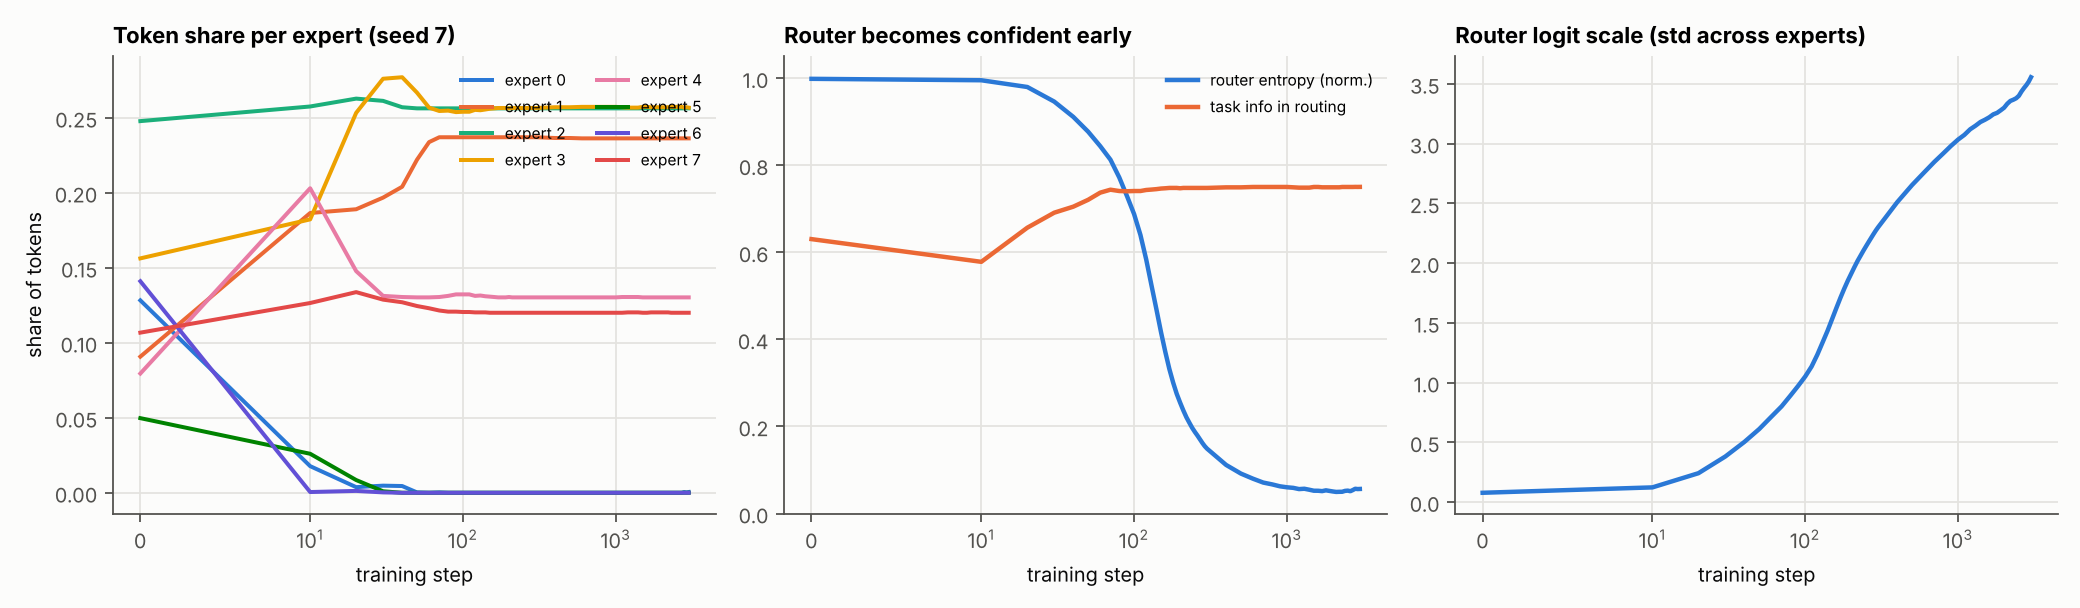

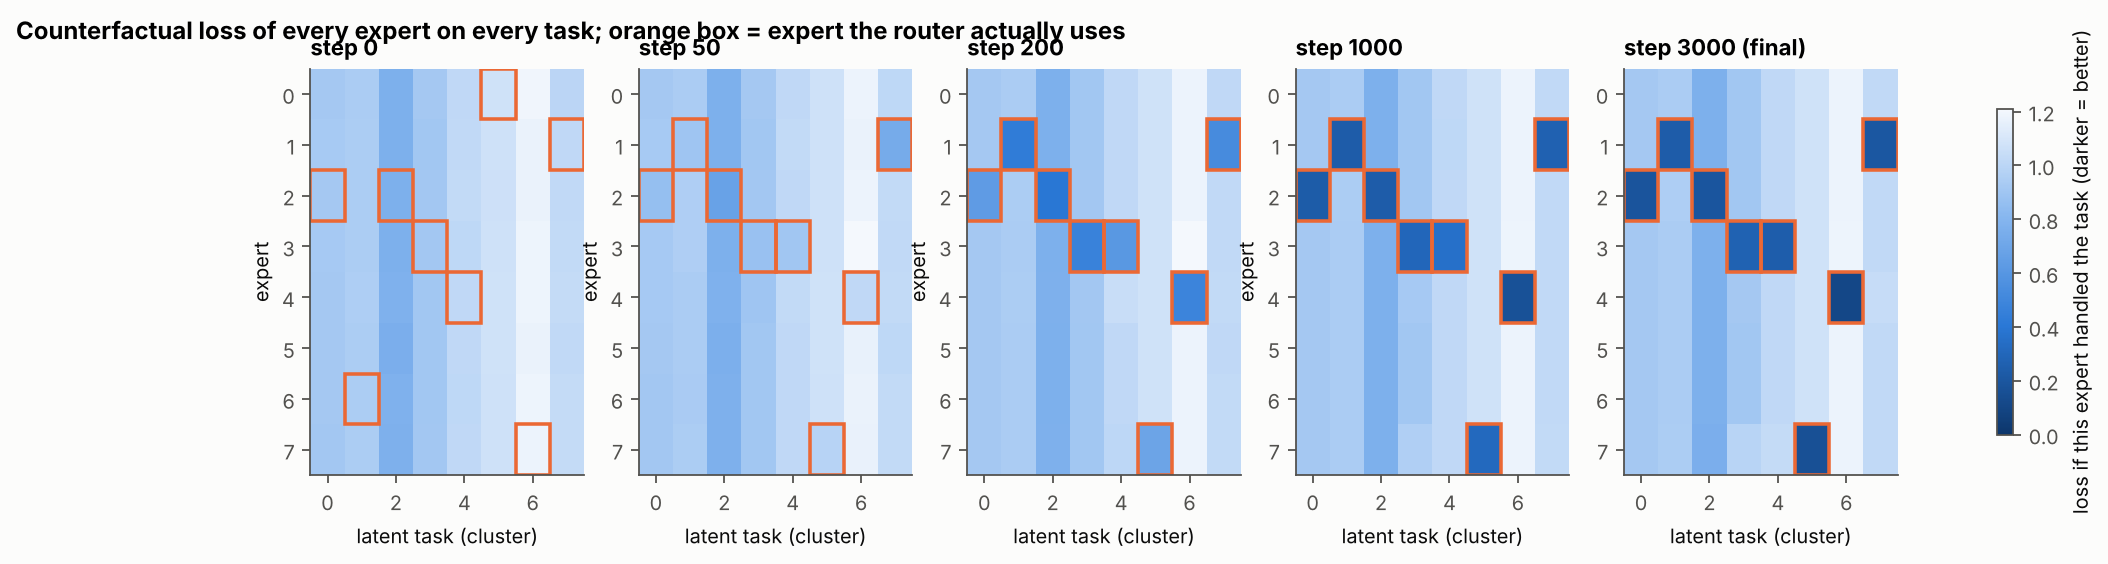

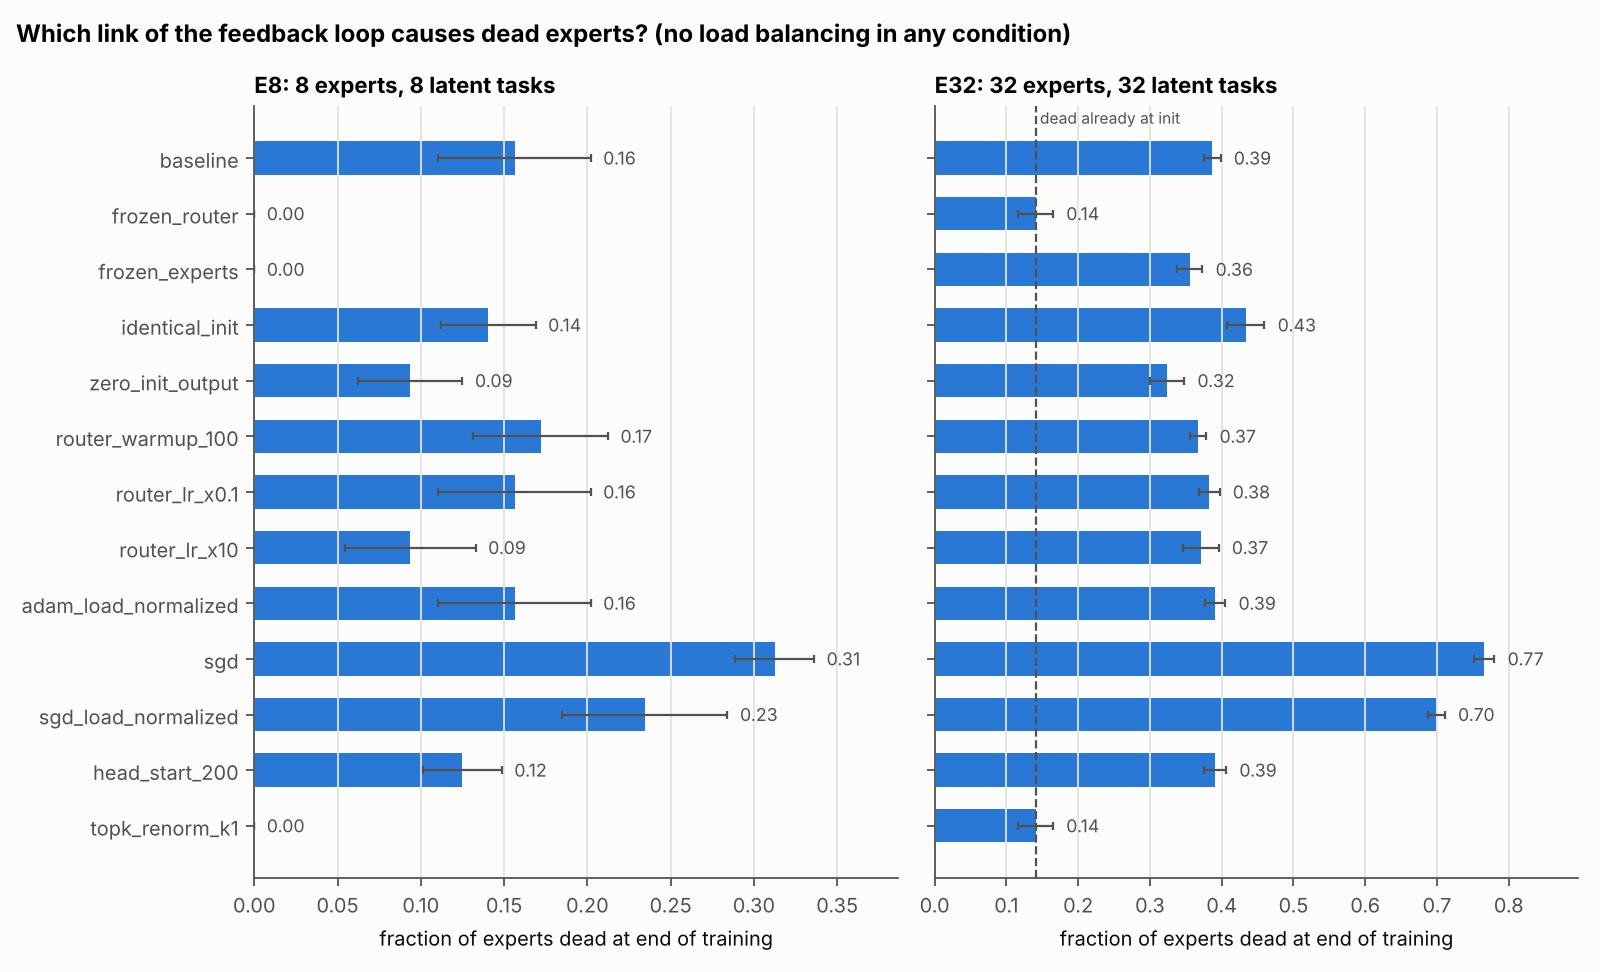

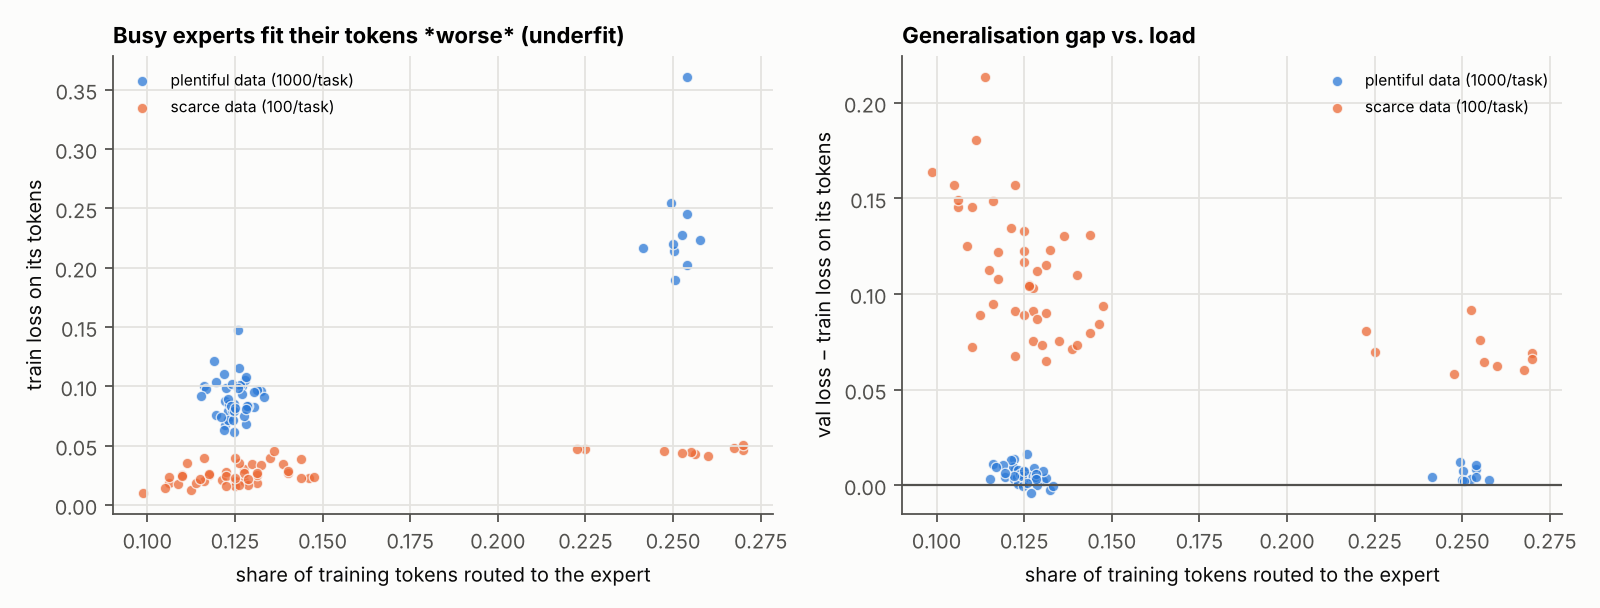

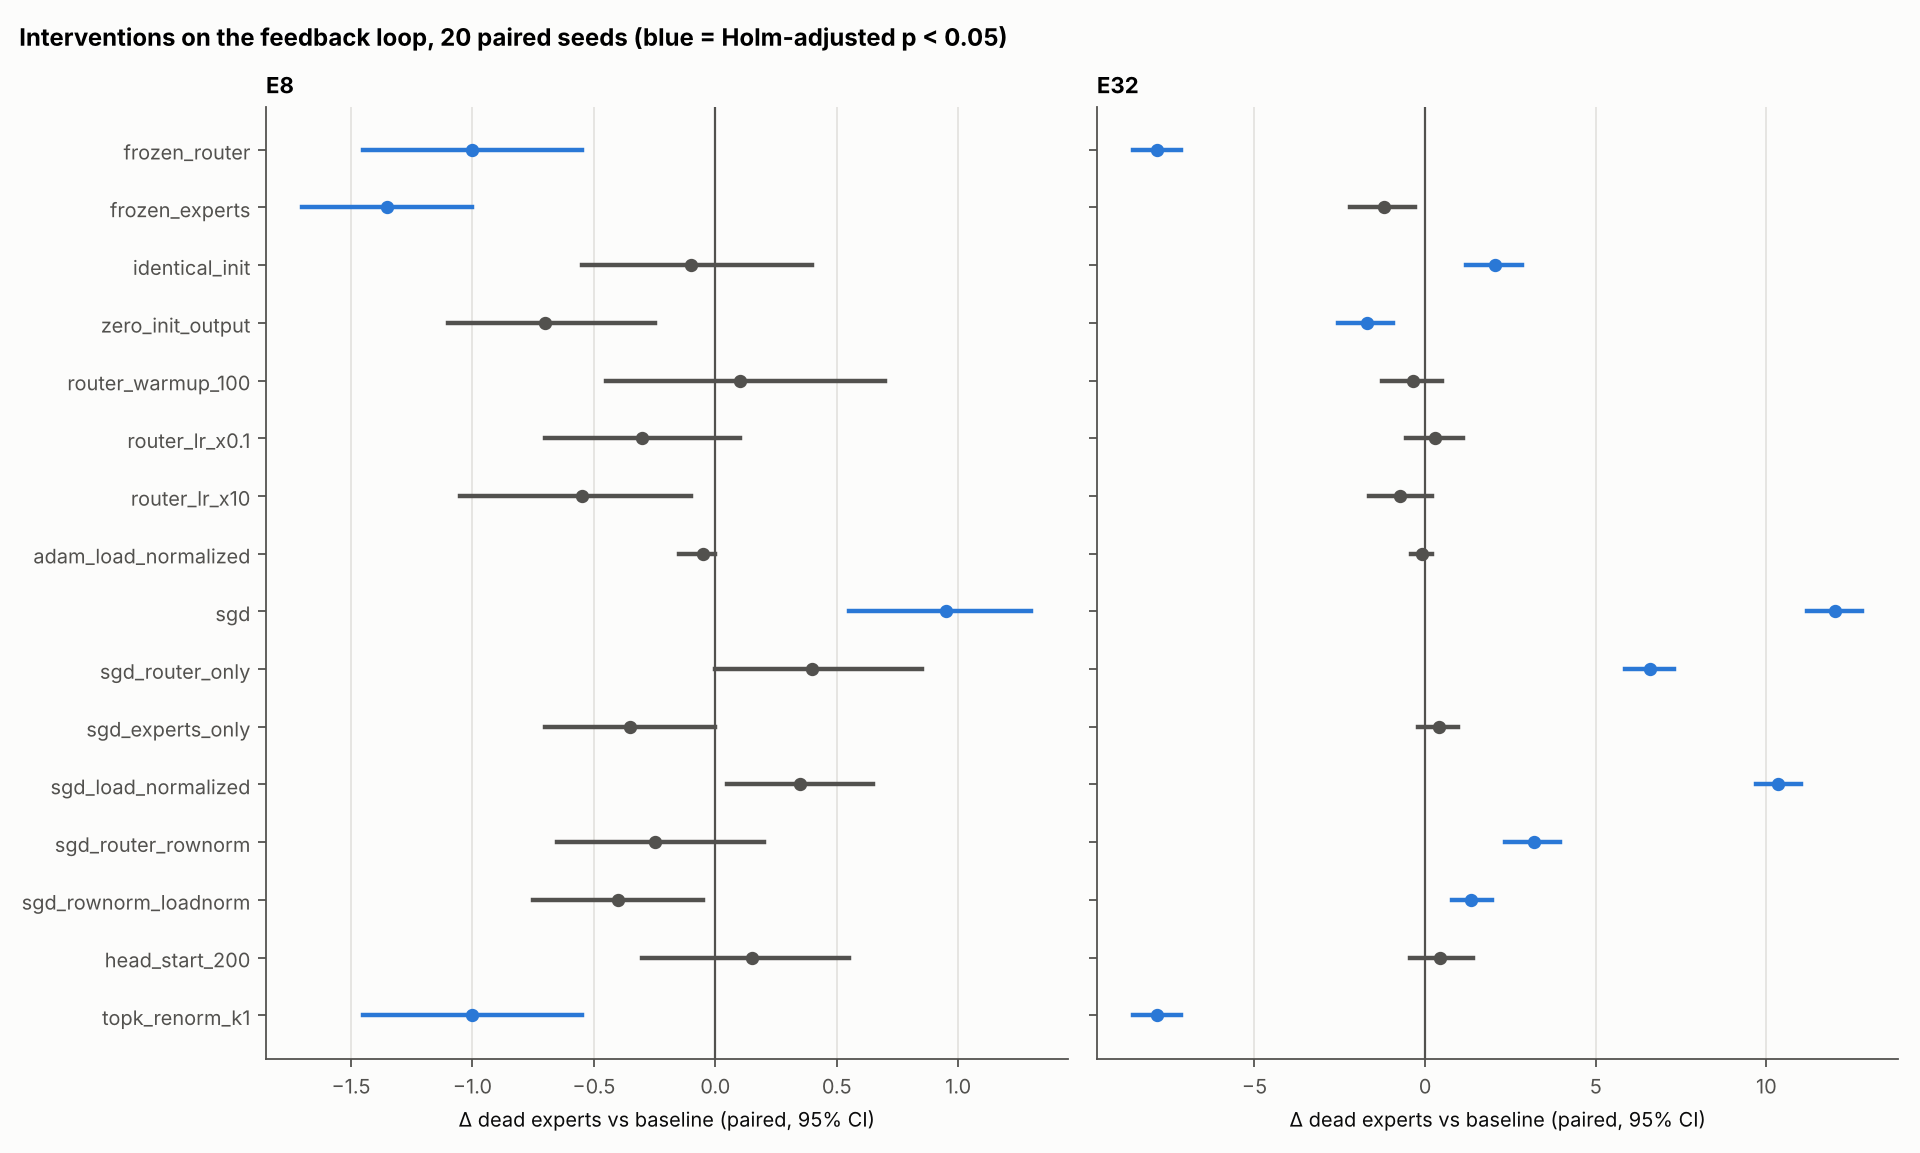

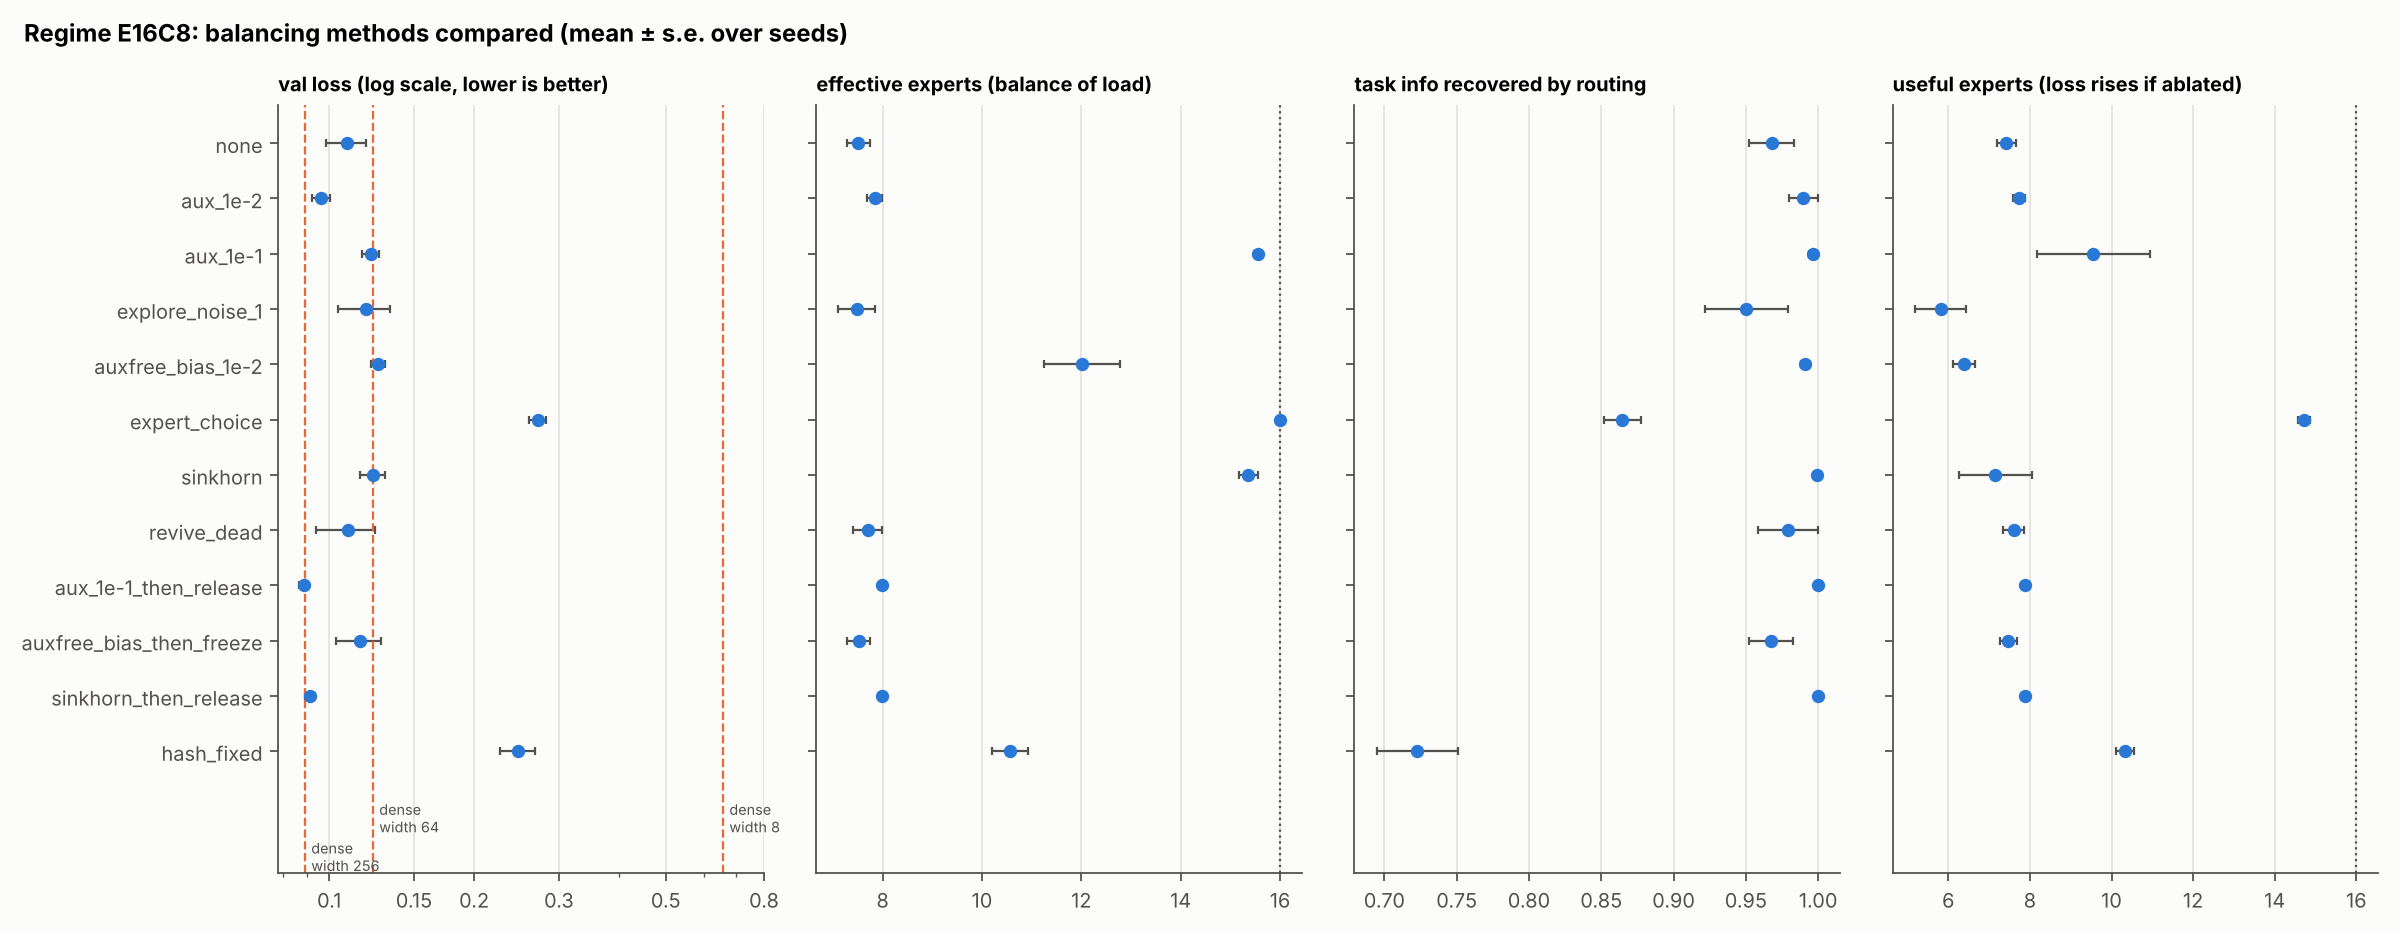

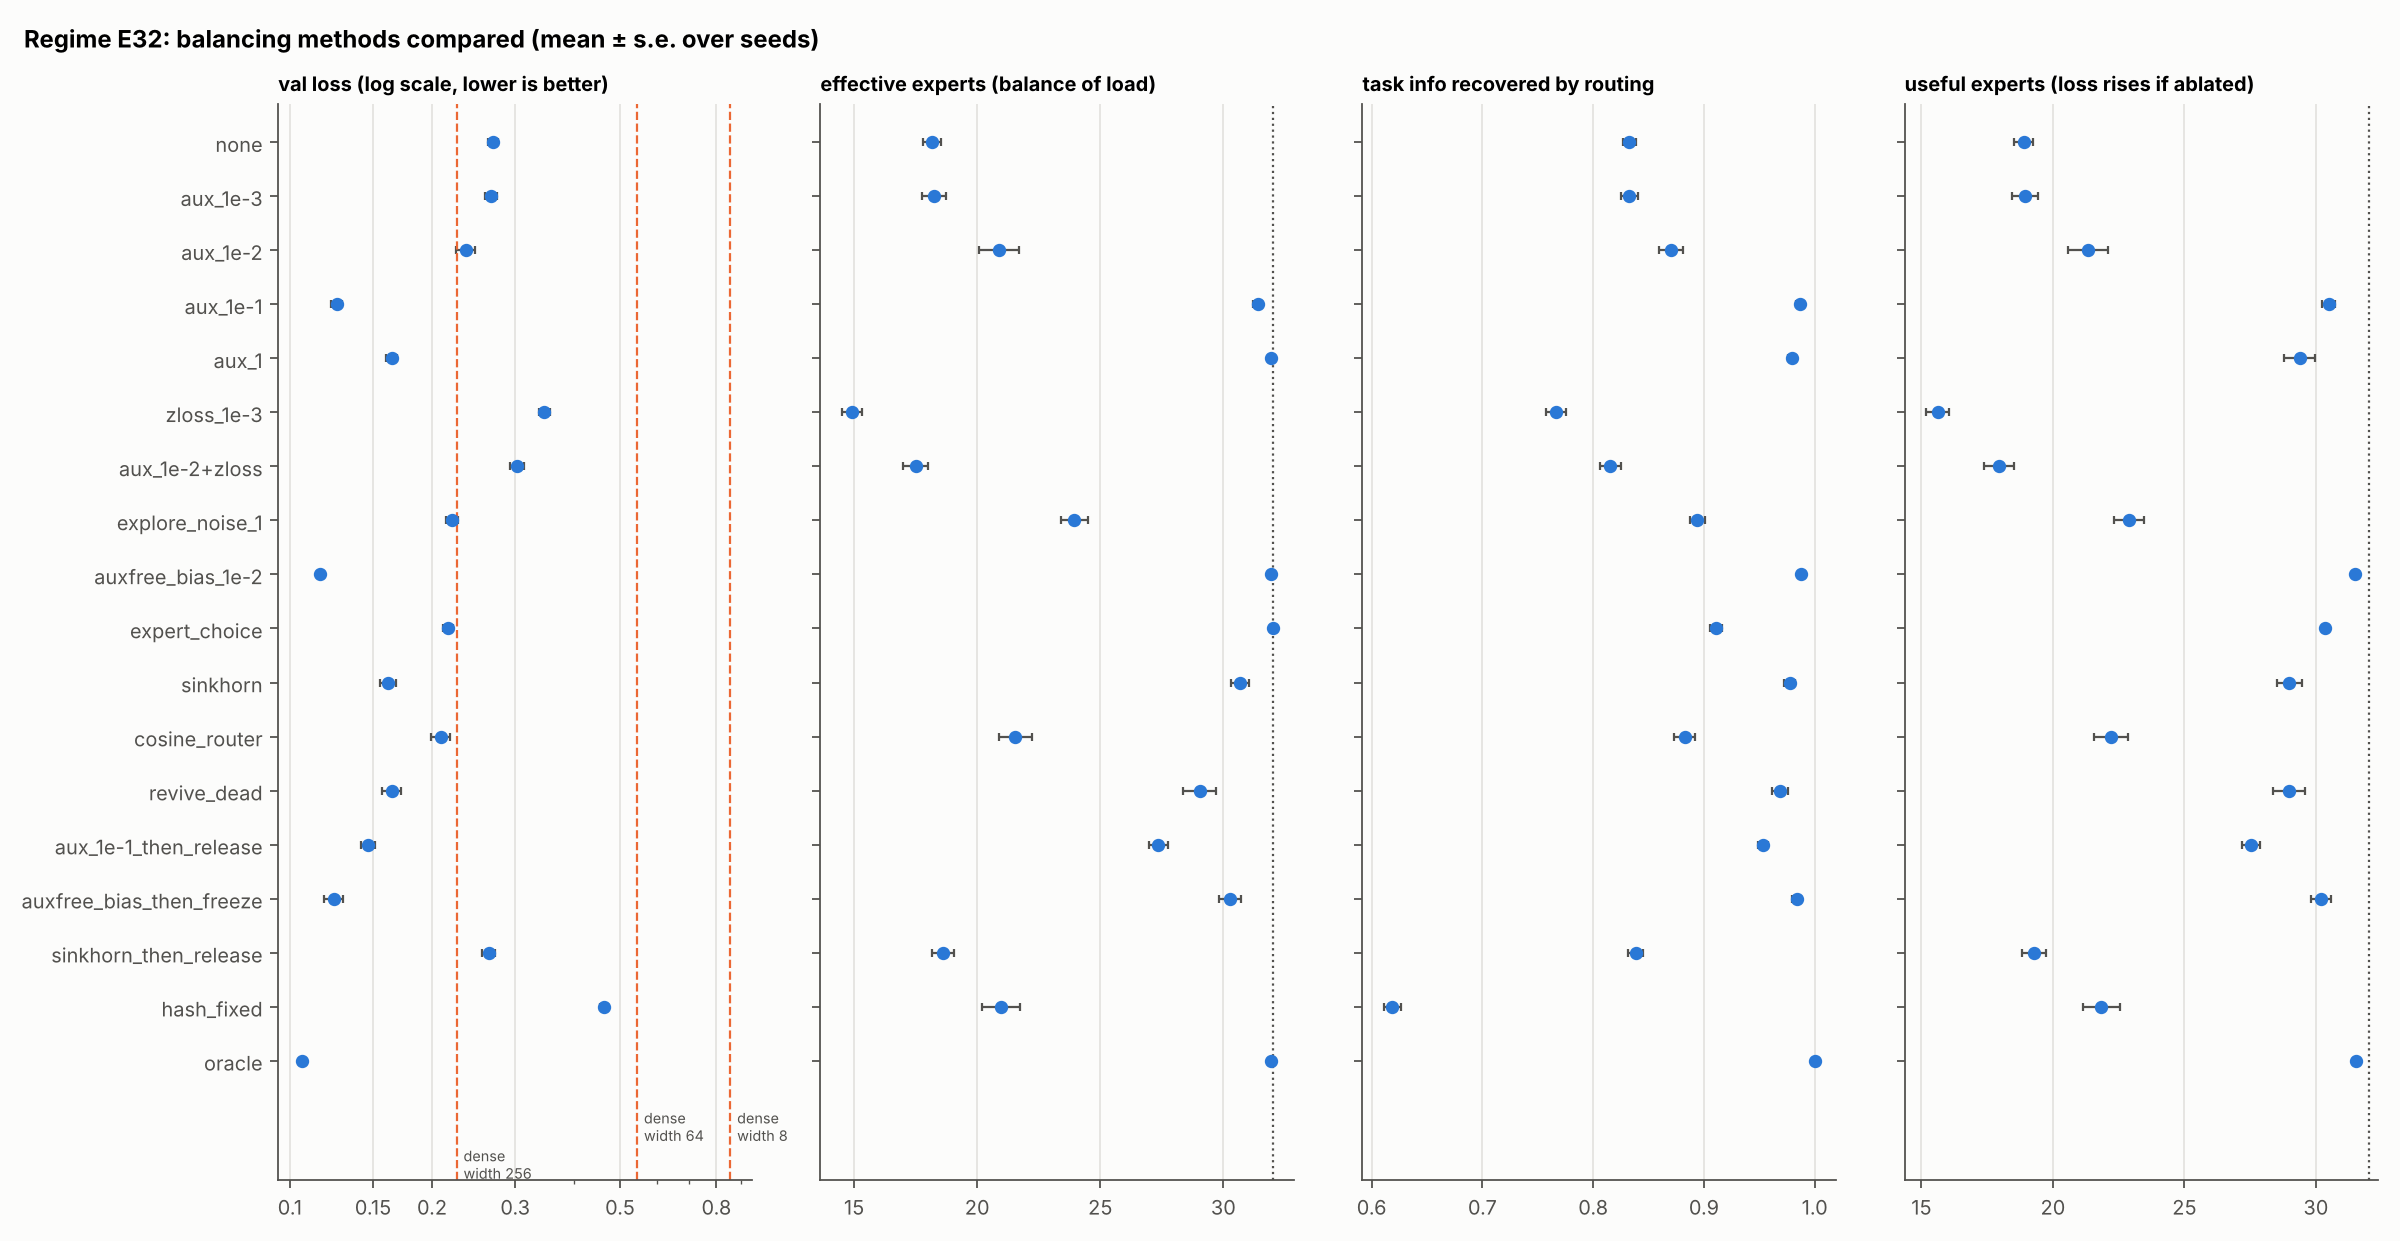

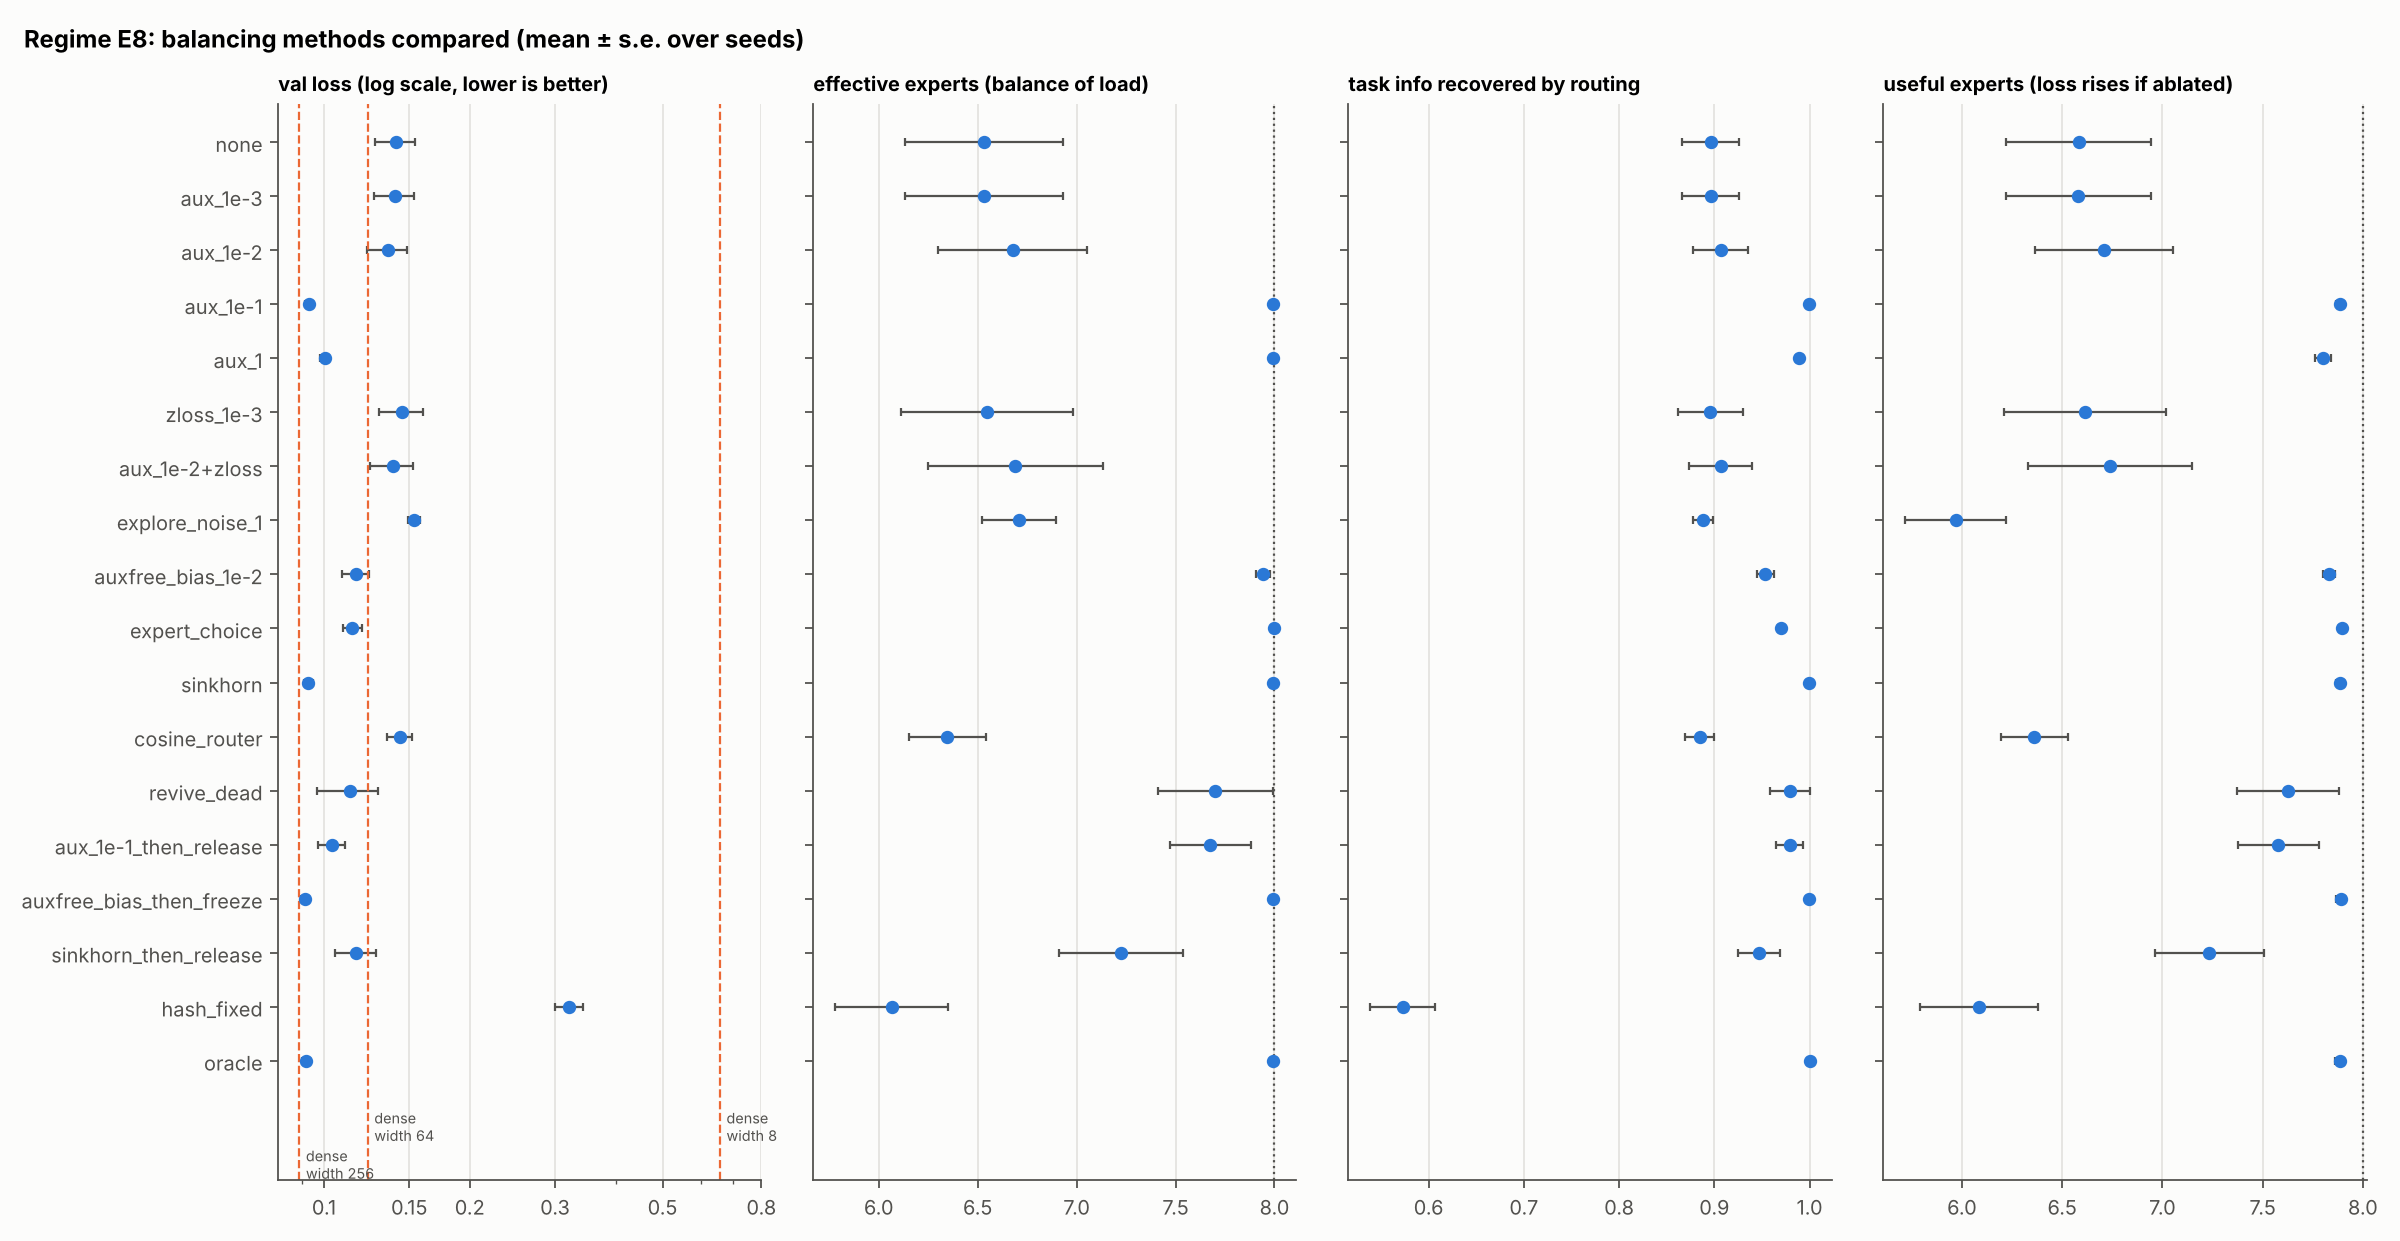

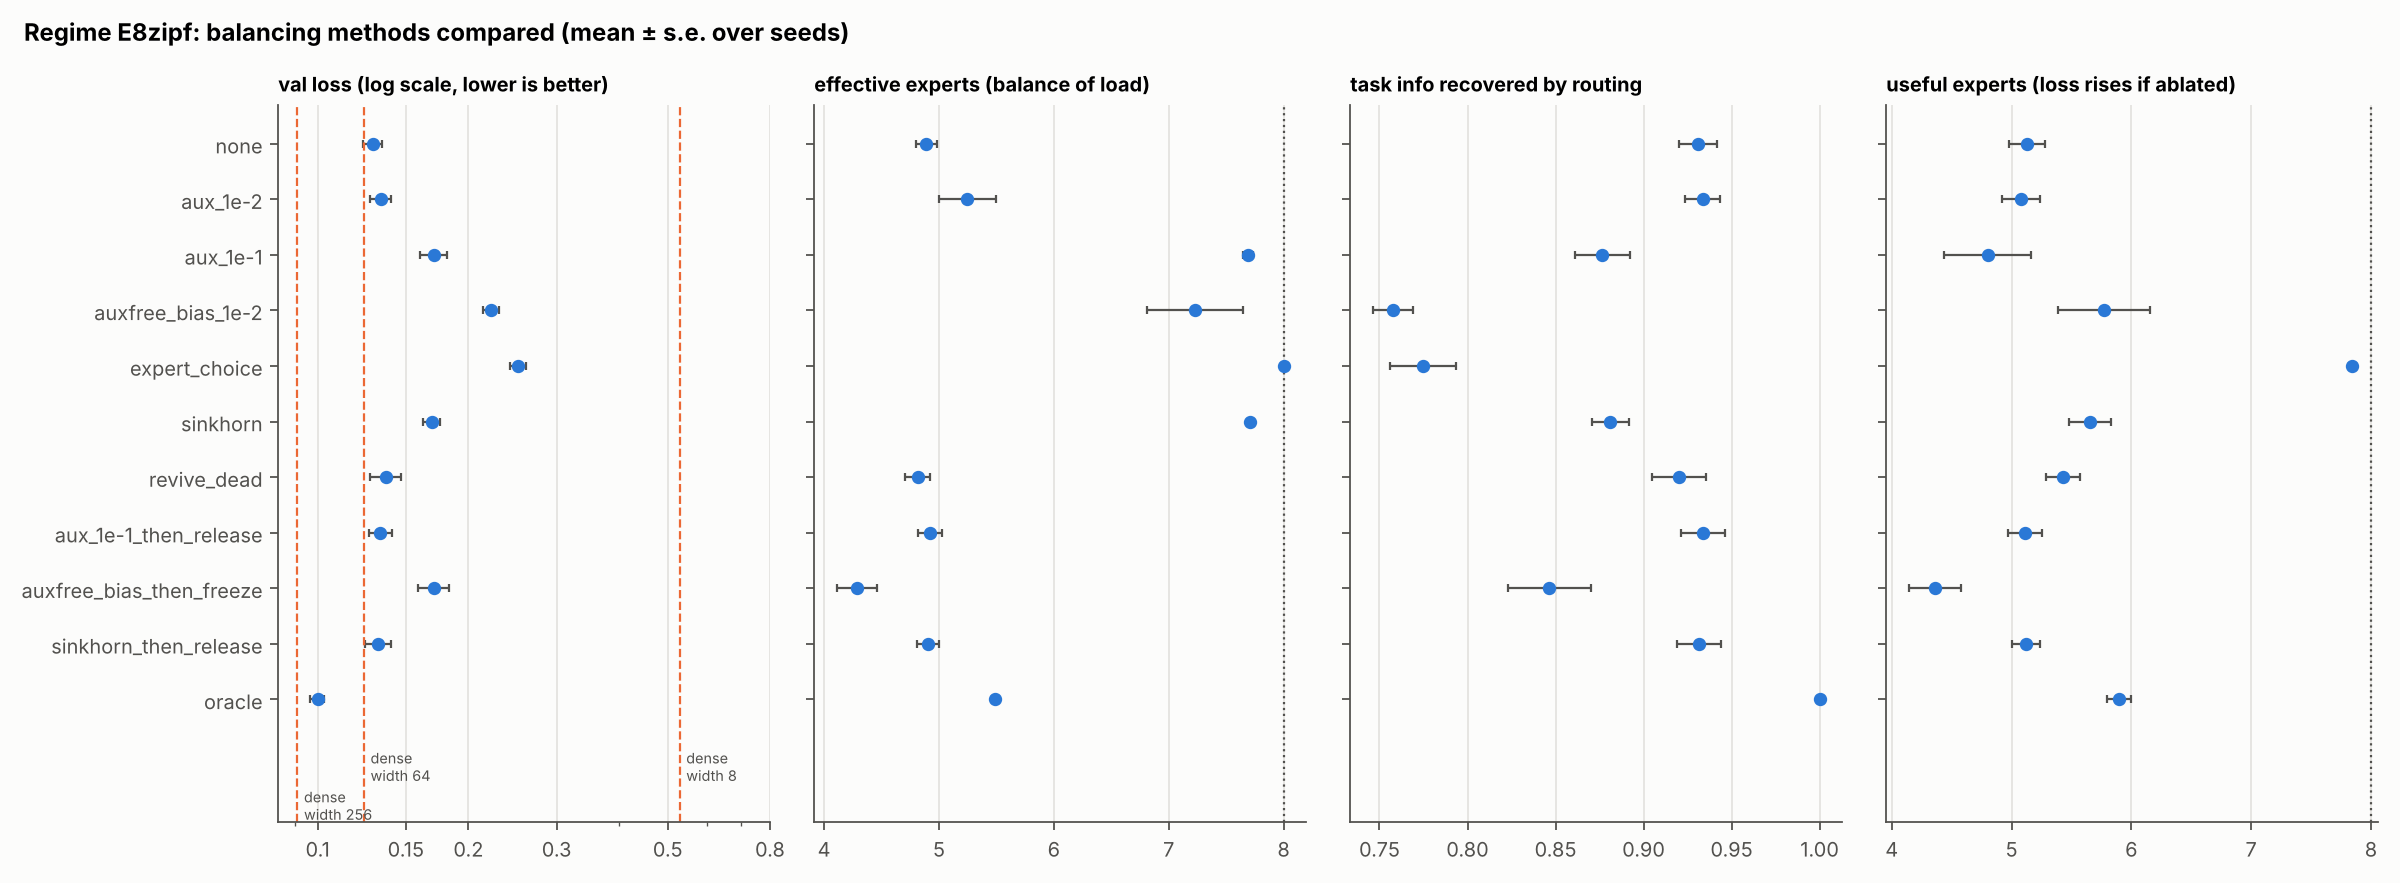

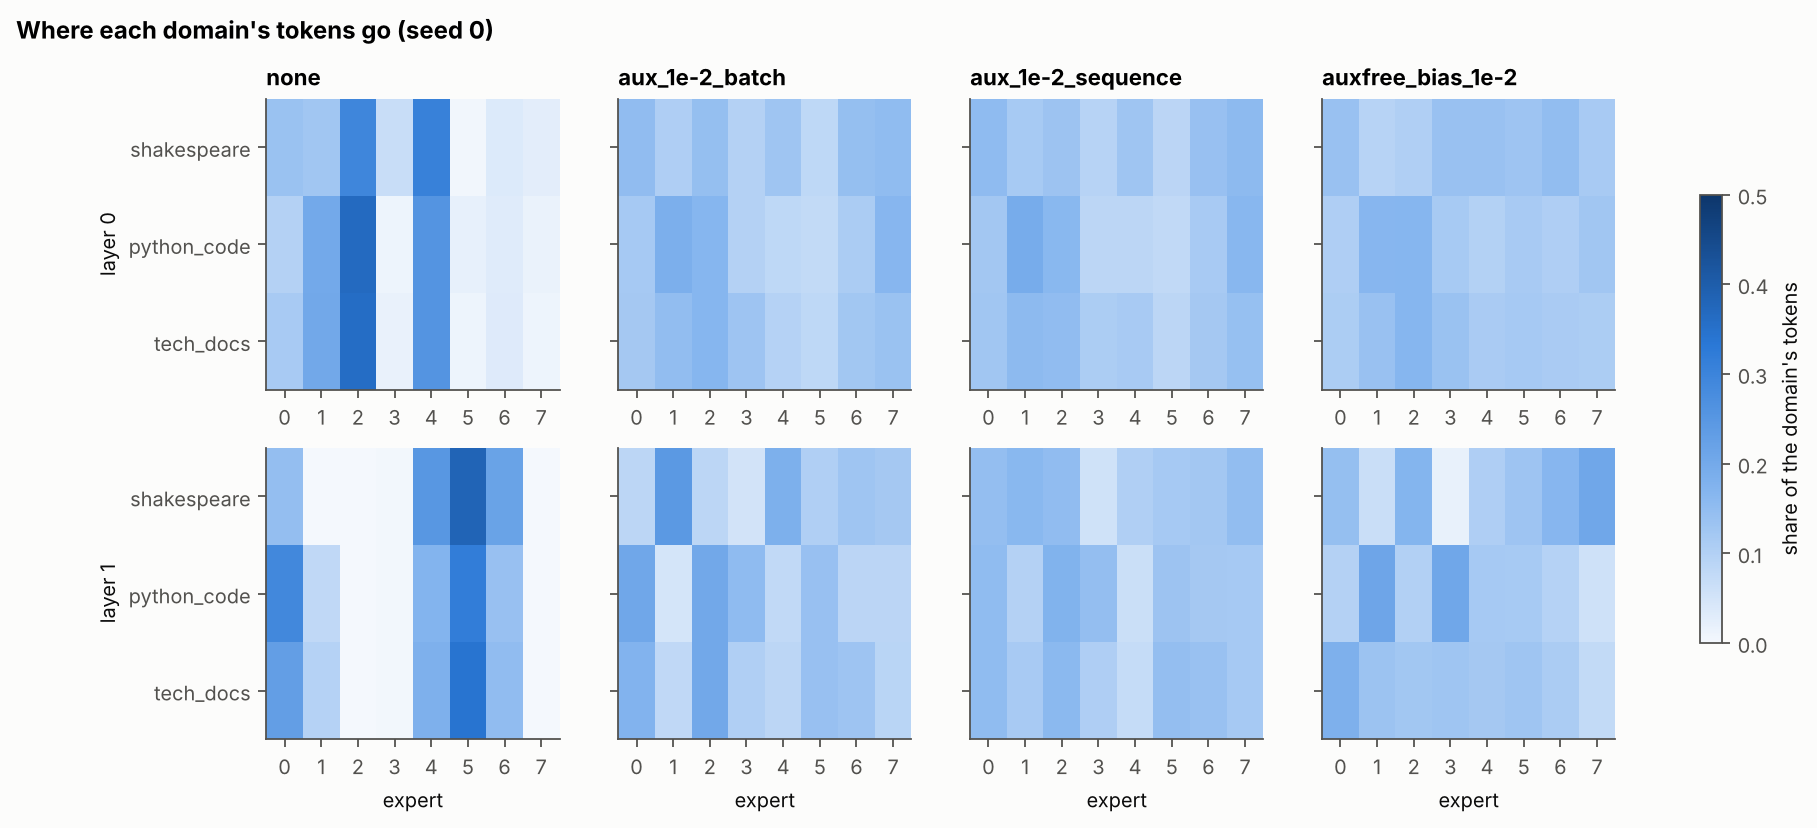

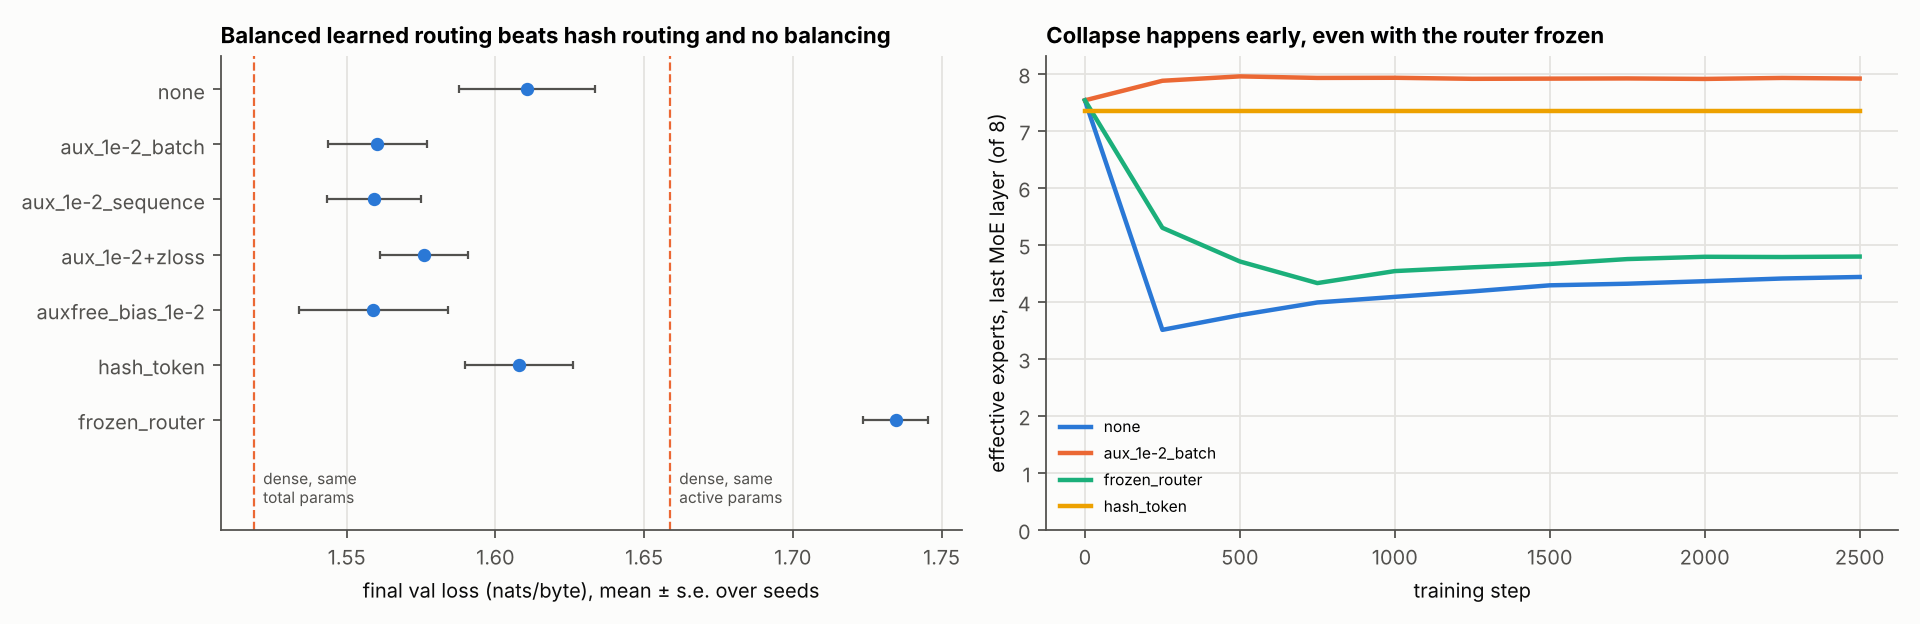

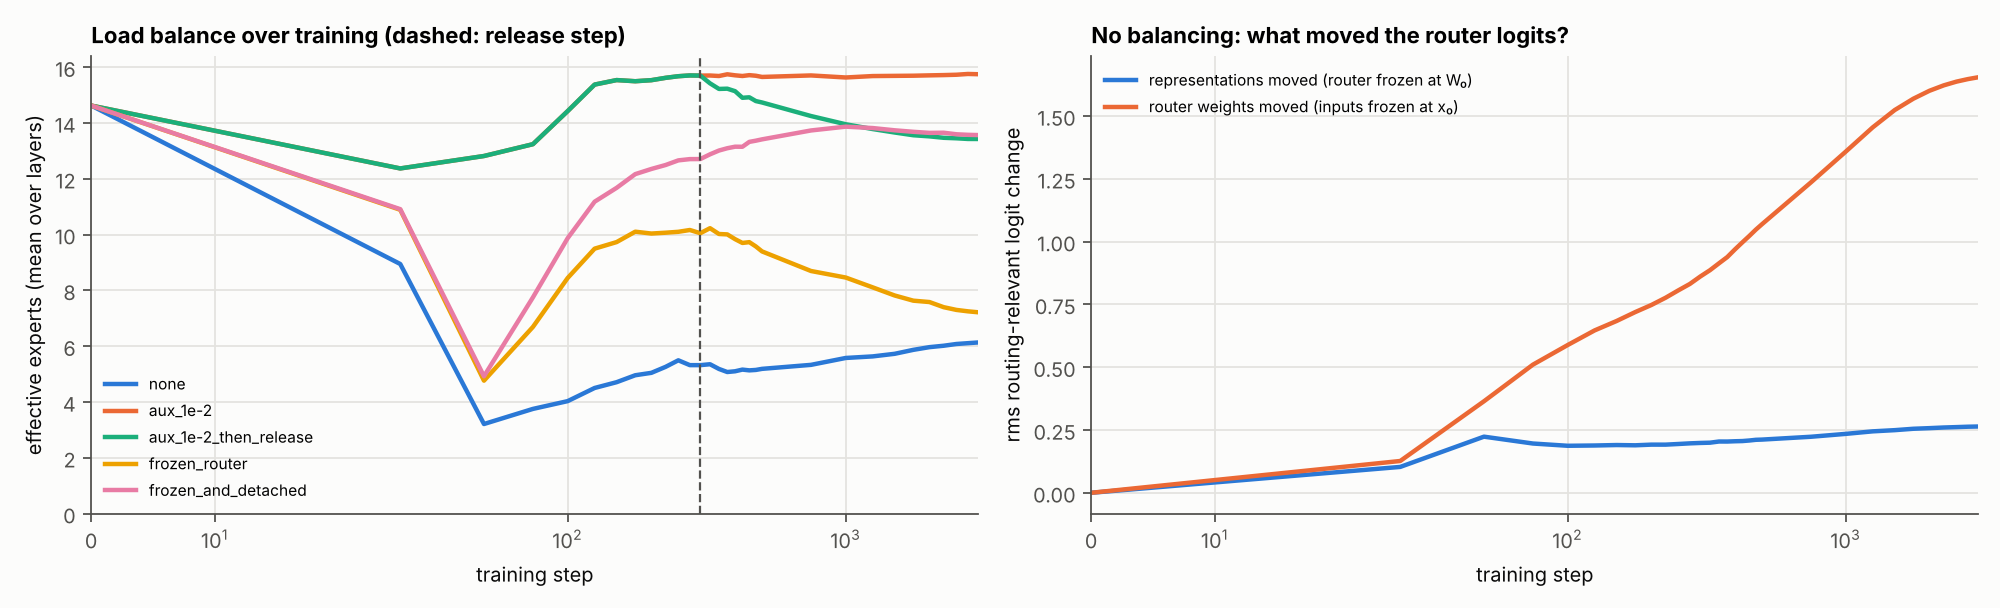

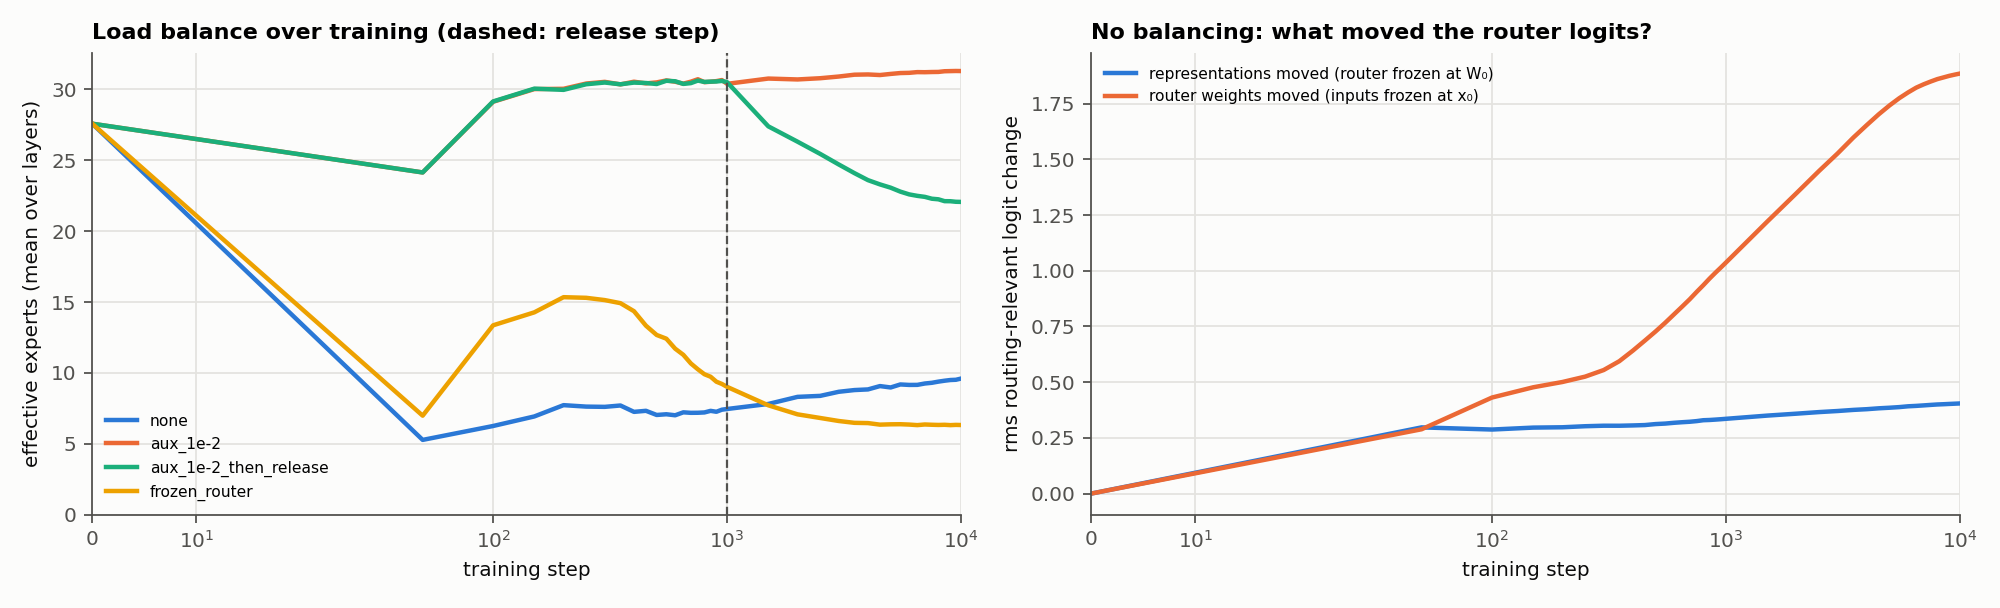

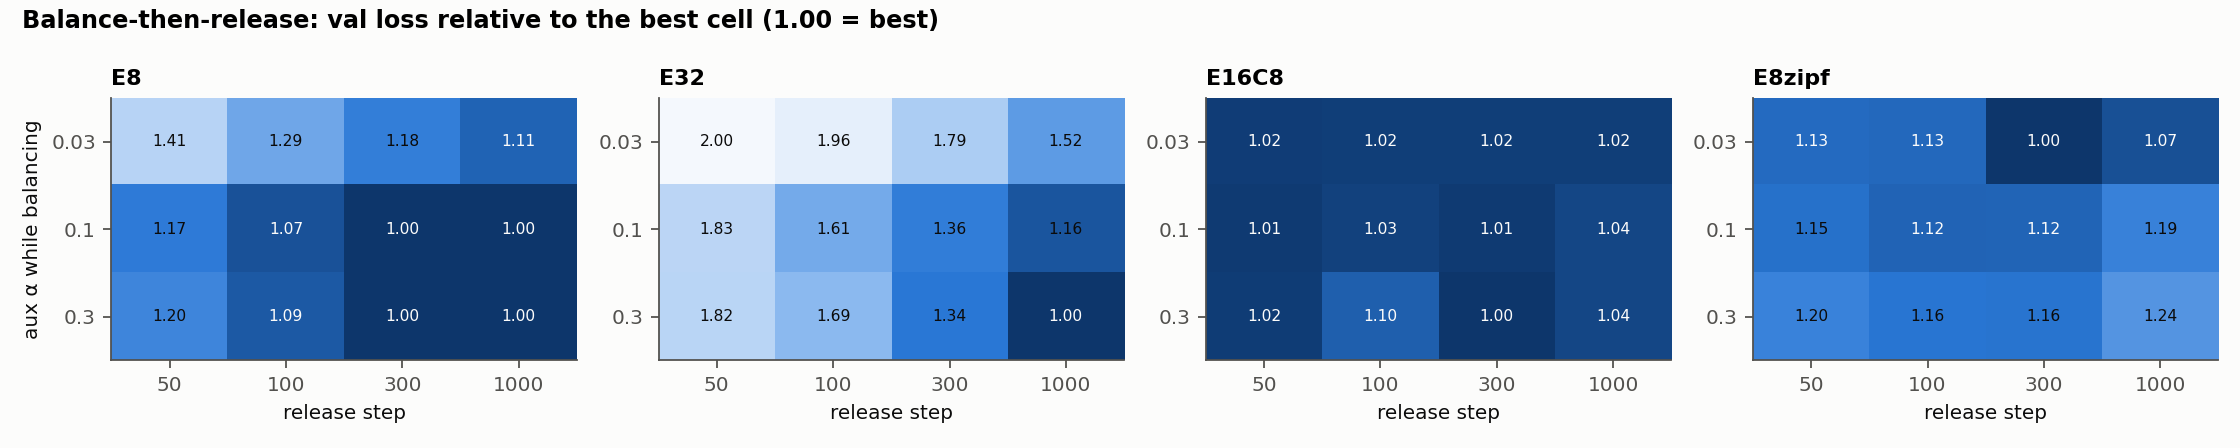

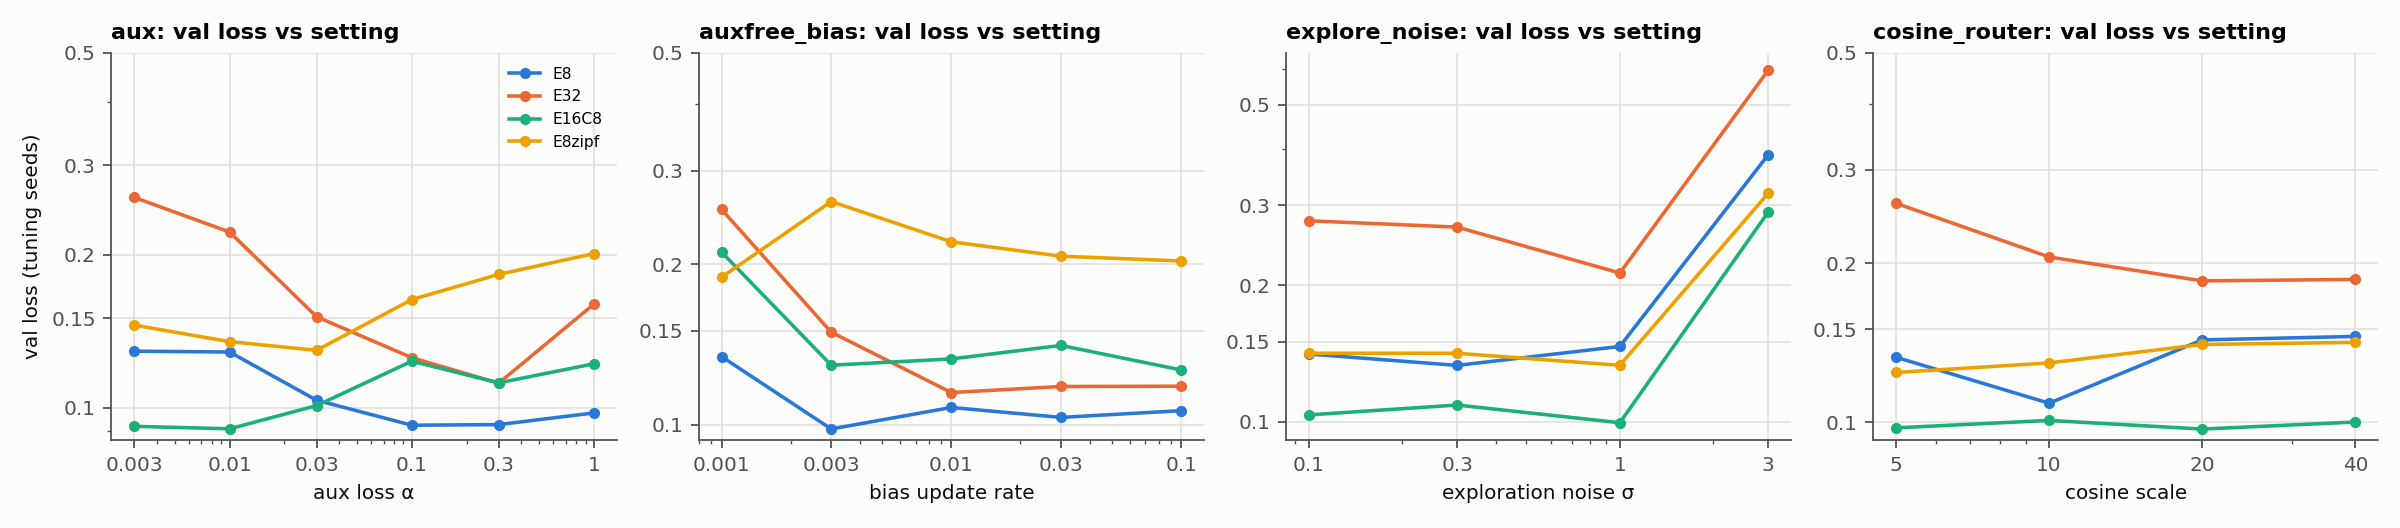

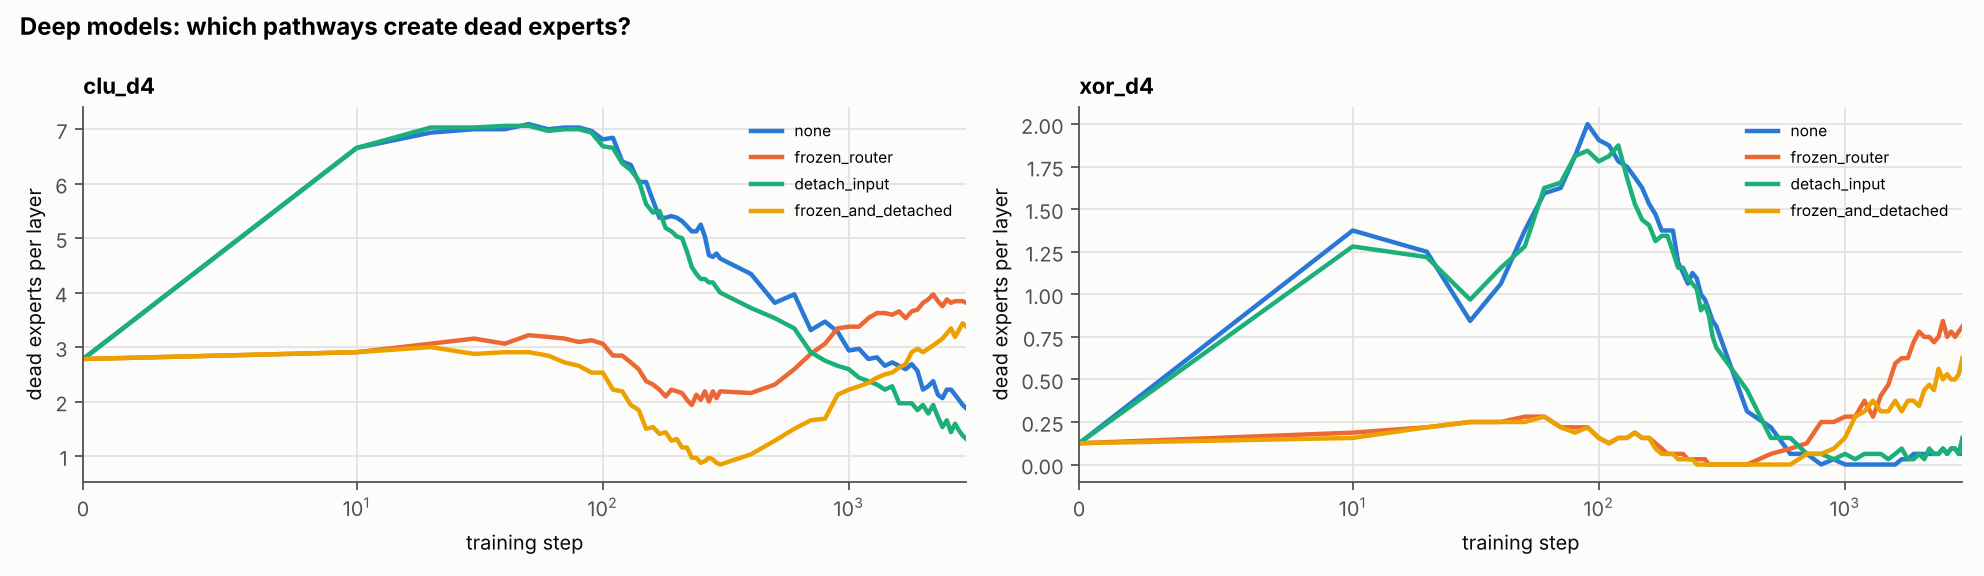

/kaggle/working/moe-lab


In [8]:
%cd experiments
!python analyze.py && python analyze2.py
from IPython.display import Image, Markdown, display
import glob
for name in sorted(glob.glob('../results/summary_*.md')):
    display(Markdown(open(name).read()))
for p in sorted(glob.glob('../results/figures/*.png')):
    display(Image(p))
%cd ..

In [9]:
# Bundle only the new outputs, to download from the Output tab and upload to the repo.
import os, zipfile
keep = ["results/e3v2_lm_gpu", "results/e7_real_checkpoints", "results/runs_e3v2_lm_gpu.csv",
        "results/summary_e3v2_gpu.md", "results/figures/e3v2_gpu_dynamics.png"]
out = "/kaggle/working/new_results.zip" if os.path.exists("/kaggle/working") else "new_results.zip"
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for k in keep:
        paths = [k] if os.path.isfile(k) else [os.path.join(d, f) for d, _, fs in os.walk(k) for f in fs]
        for p in paths:
            z.write(p)
print(out, f"{os.path.getsize(out) / 2**20:.1f} MiB:", sorted(z.namelist())[:5], "...")

/kaggle/working/new_results.zip 2.8 MiB: ['results/e3v2_lm_gpu/aux_1e-2__s0.json', 'results/e3v2_lm_gpu/aux_1e-2__s1.json', 'results/e3v2_lm_gpu/aux_1e-2__s2.json', 'results/e3v2_lm_gpu/aux_1e-2_then_release__s0.json', 'results/e3v2_lm_gpu/aux_1e-2_then_release__s1.json'] ...
